# 🎓 Anomaly Detection for Vibration-Based Fault Diagnosis
## One-Class SVM · Isolation Forest · Local Outlier Factor

**Course Context:** This notebook is a self-contained lecture on *unsupervised anomaly detection* applied to mechanical vibration monitoring. We will build a synthetic bearing vibration dataset, extract physics-informed features, and systematically compare three powerful anomaly detectors.

---

### 📚 Key References
| Paper | Contribution |
|---|---|
| Schölkopf et al., *Neural Computation* 13(7), 2001 | One-Class SVM — estimating the support of a high-dimensional distribution |
| Liu, Ting & Zhou, *IEEE ICDM*, 2008 | Isolation Forest — isolation-based anomaly detection |
| Breunig, Kriegel, Ng & Sander, *ACM SIGMOD*, 2000 | LOF — identifying density-based local outliers |
| Hariri, Kind & Brunner, *IEEE TKDE*, 2021 | Extended Isolation Forest — improved anomaly scoring |

### 🗺️ Notebook Roadmap
1. **§1** — Synthetic vibration dataset (10000 Hz, bearing inner-race fault)
2. **§2** — Feature extraction (Kurtosis, Crest Factor, Skewness, Shape Factor, Spectral Centroid)
3. **§3** — Exploratory data analysis & feature-space visualization
4. **§4** — One-Class SVM deep dive
5. **§5** — Isolation Forest deep dive
6. **§6** — Local Outlier Factor deep dive
7. **§7** — Head-to-head comparison (Confusion Matrix, Precision, Recall, F1, ROC-AUC, PR-AUC)
8. **§8** — Hyperparameter sensitivity & interactive exploration

In [1]:
# ============================================================
# §0 — Imports & Configuration
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import ListedColormap
import seaborn as sns
from scipy import stats, signal

from sklearn.svm import OneClassSVM
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    confusion_matrix, classification_report, roc_curve, auc,
    precision_recall_curve, average_precision_score, f1_score,
    precision_score, recall_score, accuracy_score, ConfusionMatrixDisplay,
    RocCurveDisplay, PrecisionRecallDisplay
)
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split

import warnings
warnings.filterwarnings('ignore')

# Aesthetics
plt.rcParams.update({
    'figure.figsize': (12, 5),
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'font.size': 11,
    'legend.fontsize': 10,
    'figure.dpi': 110,
})
sns.set_style("whitegrid")

SEED = 42
np.random.seed(SEED)
print("✅ All libraries loaded successfully.")

✅ All libraries loaded successfully.


---
## §1 — Synthetic Vibration Dataset

### Physical Setup (what we're simulating)
Imagine an **accelerometer** mounted on a bearing housing of a rotating machine (e.g., a pump or electric motor) spinning at **1800 RPM (30 Hz)**. The sensor samples at **$f_s = 10000$ Hz**.

**Normal operation:** The vibration is dominated by the shaft rotation frequency and its harmonics, plus broadband machine noise.

**Faulty operation (inner-race defect):** When a small spall develops on the bearing inner race, each time a rolling element passes over the defect it produces a **short impulse**. This shows up as:
- Periodic **impact bursts** at the Ball Pass Frequency Inner race (BPFI ≈ 5–7× shaft speed)
- **Increased kurtosis** (heavy tails from impulsive events)
- **Higher crest factor** (spiky peaks relative to RMS)
- **Changed skewness** (asymmetric distribution)

We'll generate 500 "measurement windows" (each 0.5 s long = 5000 samples), with **~10% being faulty**.

In [2]:
# ============================================================
# §1 — Generate Synthetic Vibration Data
# ============================================================

fs = 10000          # Sampling frequency (Hz) - Increased to 10kHz to capture high-freq resonance
T_window = 0.5     # Window length in seconds
N_samples = int(fs * T_window)  # 5,000 samples per window
n_windows = 500    # Total number of measurement windows
fault_ratio = 0.10 # ~10% faulty windows
shaft_freq = 30    # Shaft rotation frequency (Hz) — 1800 RPM
bpfi = 5.2 * shaft_freq  # Ball Pass Frequency Inner race ≈ 156 Hz

t = np.arange(N_samples) / fs  # Time vector for one window

def generate_normal_vibration(t, shaft_freq, fs):
    """Normal bearing vibration: shaft harmonics + broadband noise."""
    sig = (1.0 * np.sin(2 * np.pi * shaft_freq * t) +
           0.5 * np.sin(2 * np.pi * 2 * shaft_freq * t + 0.3) +
           0.3 * np.sin(2 * np.pi * 3 * shaft_freq * t + 1.1) +
           0.15 * np.sin(2 * np.pi * 4 * shaft_freq * t + 0.7))
    noise = 0.4 * np.random.randn(len(t))
    return sig + noise

def generate_faulty_vibration(t, shaft_freq, bpfi, fs):
    """Inner-race fault: normal vibration + periodic impulses at BPFI."""
    normal = generate_normal_vibration(t, shaft_freq, fs)
    
    # Periodic impulses at BPFI — short exponentially-decaying bursts
    impulse_period = 1.0 / bpfi
    impulse_times = np.arange(0, t[-1], impulse_period)
    impulses = np.zeros_like(t)
    for ti in impulse_times:
        idx = np.argmin(np.abs(t - ti))
        if idx < len(t) - 10:
            # Exponentially-decaying impact burst (ring-down)
            # Duration ~15ms -> 150 samples at 10kHz
            burst_len = min(150, len(t) - idx)
            
            # Decay constant: tau ~ 2ms -> 20 samples at 10kHz
            burst = np.exp(-np.arange(burst_len) / 20.0) * np.random.uniform(2.5, 4.5)
            
            # High-frequency resonance (3500 Hz) with Phase Reset
            # Using relative time (np.arange) ensures consistent waveform shape
            carrier = np.sin(2 * np.pi * 3500 * np.arange(burst_len) / fs)
            
            impulses[idx:idx + burst_len] += burst * carrier
    
    # Add some extra amplitude modulation (fault severity variation)
    am = 1.0 + 0.3 * np.sin(2 * np.pi * bpfi * t)
    return normal * am + impulses

# --- Generate all windows ---
signals = []
labels = []  # 0 = normal, 1 = fault

n_faulty = int(n_windows * fault_ratio)
n_normal = n_windows - n_faulty

for _ in range(n_normal):
    signals.append(generate_normal_vibration(t, shaft_freq, fs))
    labels.append(0)

for _ in range(n_faulty):
    signals.append(generate_faulty_vibration(t, shaft_freq, bpfi, fs))
    labels.append(1)

# Shuffle
signals = np.array(signals)
labels = np.array(labels)
shuffle_idx = np.random.permutation(n_windows)
signals = signals[shuffle_idx]
labels = labels[shuffle_idx]

print(f"Dataset: {n_windows} windows  |  Normal: {np.sum(labels==0)}  |  Faulty: {np.sum(labels==1)}")
print(f"Window shape: {signals[0].shape}  |  fs = {fs} Hz  |  Duration = {T_window} s")

Dataset: 500 windows  |  Normal: 450  |  Faulty: 50
Window shape: (5000,)  |  fs = 10000 Hz  |  Duration = 0.5 s


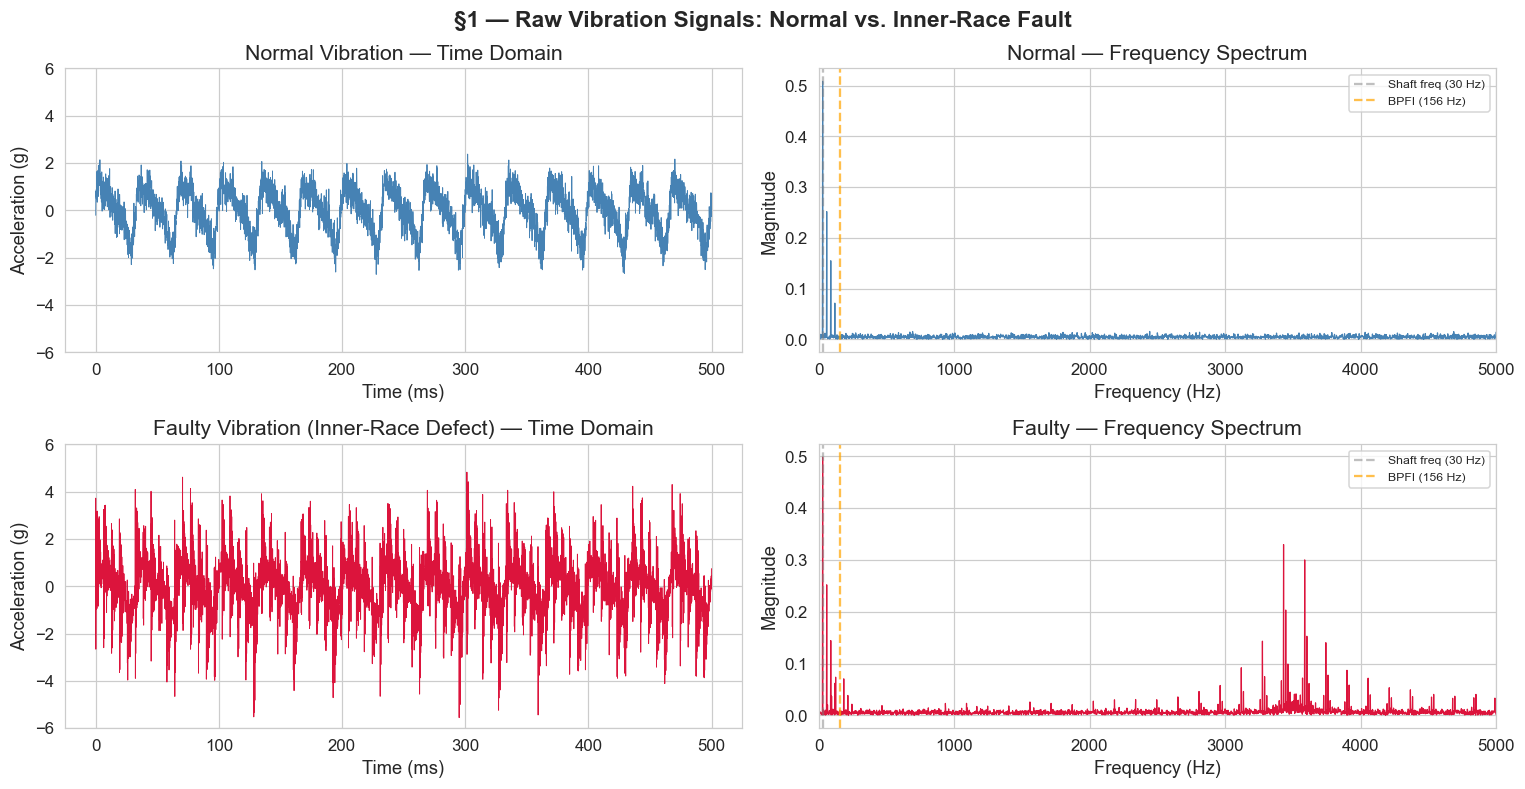

🔍 OBSERVE: The faulty signal shows impulsive spikes in time-domain
   and elevated energy near BPFI and the 3500 Hz resonance in the frequency domain.


In [3]:
# ============================================================
# §1b — Visualize Example Signals: Normal vs. Faulty
# ============================================================
fig, axes = plt.subplots(2, 2, figsize=(14, 7))

# Pick examples
idx_normal = np.where(labels == 0)[0][0]
idx_fault = np.where(labels == 1)[0][0]

# --- Time-domain ---
axes[0, 0].plot(t * 1000, signals[idx_normal], color='steelblue', linewidth=0.6)
axes[0, 0].set_title('Normal Vibration — Time Domain')
axes[0, 0].set_ylabel('Acceleration (g)')
axes[0, 0].set_xlabel('Time (ms)')
axes[0, 0].set_ylim(-6, 6)

axes[1, 0].plot(t * 1000, signals[idx_fault], color='crimson', linewidth=0.6)
axes[1, 0].set_title('Faulty Vibration (Inner-Race Defect) — Time Domain')
axes[1, 0].set_ylabel('Acceleration (g)')
axes[1, 0].set_xlabel('Time (ms)')
axes[1, 0].set_ylim(-6, 6)

# --- Frequency-domain (FFT) ---
for i, (idx, color, title) in enumerate([
    (idx_normal, 'steelblue', 'Normal — Frequency Spectrum'),
    (idx_fault, 'crimson', 'Faulty — Frequency Spectrum')
]):
    freqs = np.fft.rfftfreq(N_samples, 1/fs)
    fft_mag = np.abs(np.fft.rfft(signals[idx])) / N_samples
    axes[i, 1].plot(freqs, fft_mag, color=color, linewidth=0.8)
    axes[i, 1].set_title(title)
    axes[i, 1].set_xlabel('Frequency (Hz)')
    axes[i, 1].set_ylabel('Magnitude')
    axes[i, 1].set_xlim(0, 5000)  # Show up to Nyquist (5kHz) to see the 3.5kHz resonance
    # Mark shaft frequency and BPFI
    axes[i, 1].axvline(shaft_freq, color='gray', linestyle='--', alpha=0.5, label=f'Shaft freq ({shaft_freq} Hz)')
    axes[i, 1].axvline(bpfi, color='orange', linestyle='--', alpha=0.7, label=f'BPFI ({bpfi:.0f} Hz)')
    axes[i, 1].legend(fontsize=8)

plt.tight_layout()
plt.suptitle('§1 — Raw Vibration Signals: Normal vs. Inner-Race Fault', y=1.02, fontsize=15, fontweight='bold')
plt.show()

print("🔍 OBSERVE: The faulty signal shows impulsive spikes in time-domain")
print("   and elevated energy near BPFI and the 3500 Hz resonance in the frequency domain.")

---
## §2 — Feature Extraction

We extract **5 features** from each vibration window. Each has a clear physical meaning for fault detection:

| Feature | Formula | Physical Meaning |
|---|---|---|
| **Kurtosis** | $\kappa = \frac{\frac{1}{N}\sum(x_i - \bar{x})^4}{\left(\frac{1}{N}\sum(x_i - \bar{x})^2\right)^2}$ | Measures "tailedness" of the distribution. Normal vibration ≈ 3 (Gaussian). Impulsive faults → kurtosis >> 3. *The single most important indicator for bearing faults.* |
| **Crest Factor** | $CF = \frac{\max(\|x\|)}{x_{rms}}$ | Ratio of peak to RMS. A high crest factor means sharp spikes exist — classic signature of impacts. |
| **Skewness** | $S = \frac{\frac{1}{N}\sum(x_i - \bar{x})^3}{\left(\frac{1}{N}\sum(x_i - \bar{x})^2\right)^{3/2}}$ | Asymmetry of the distribution. Bearing faults with unidirectional impacts can shift skewness away from 0. |
| **Shape Factor** | $SF = \frac{x_{rms}}{\frac{1}{N}\sum\|x_i\|}$ | Ratio of RMS to mean absolute value. Sensitive to waveform shape changes. For a sine wave ≈ 1.11; impulses increase it. |
| **Spectral Centroid** | $SC = \frac{\sum f_k \cdot \|X(f_k)\|}{\sum \|X(f_k)\|}$ | The "center of mass" of the spectrum. Faults shift energy to higher frequencies → spectral centroid increases. |

In [4]:
# ============================================================
# §2 — Feature Extraction Functions
# ============================================================

def extract_features(sig, fs):
    """Extract 5 vibration-diagnostic features from a time-domain signal."""
    N = len(sig)
    
    # --- Time-domain features ---
    rms = np.sqrt(np.mean(sig**2))
    mean_abs = np.mean(np.abs(sig))
    peak = np.max(np.abs(sig))
    
    kurtosis    = stats.kurtosis(sig, fisher=False)   # Fisher=False → normal dist = 3
    crest_factor = peak / rms if rms > 0 else 0
    skewness    = stats.skew(sig)
    shape_factor = rms / mean_abs if mean_abs > 0 else 0
    
    # --- Frequency-domain feature ---
    freqs = np.fft.rfftfreq(N, 1/fs)
    fft_mag = np.abs(np.fft.rfft(sig))
    spectral_centroid = np.sum(freqs * fft_mag) / np.sum(fft_mag) if np.sum(fft_mag) > 0 else 0
    
    return [kurtosis, crest_factor, skewness, shape_factor, spectral_centroid]

# --- Extract features for all windows ---
feature_names = ['Kurtosis', 'Crest Factor', 'Skewness', 'Shape Factor', 'Spectral Centroid']
features_list = [extract_features(signals[i], fs) for i in range(n_windows)]
df = pd.DataFrame(features_list, columns=feature_names)
df['Label'] = labels
df['Label_str'] = df['Label'].map({0: 'Normal', 1: 'Fault'})

print("Feature matrix shape:", df.shape)
print("\n--- Feature Statistics (Normal windows) ---")
print(df[df.Label == 0][feature_names].describe().round(3))
print("\n--- Feature Statistics (Faulty windows) ---")
print(df[df.Label == 1][feature_names].describe().round(3))

Feature matrix shape: (500, 7)

--- Feature Statistics (Normal windows) ---
       Kurtosis  Crest Factor  Skewness  Shape Factor  Spectral Centroid
count   450.000       450.000   450.000       450.000            450.000
mean      2.407         3.022    -0.322         1.211           2328.293
std       0.029         0.164     0.019         0.003             14.202
min       2.324         2.663    -0.398         1.202           2282.121
25%       2.385         2.903    -0.334         1.209           2319.139
50%       2.407         2.999    -0.321         1.211           2328.981
75%       2.428         3.109    -0.310         1.213           2338.185
max       2.483         3.687    -0.268         1.221           2361.721

--- Feature Statistics (Faulty windows) ---
       Kurtosis  Crest Factor  Skewness  Shape Factor  Spectral Centroid
count    50.000        50.000    50.000        50.000             50.000
mean      4.005         4.161    -0.258         1.322           2626.071
std

---
## §3 — Exploratory Data Analysis

Before we throw ML models at the data, let's **see** how normal and faulty windows differ in feature space. This builds intuition for *why* the anomaly detectors will (or won't) work.

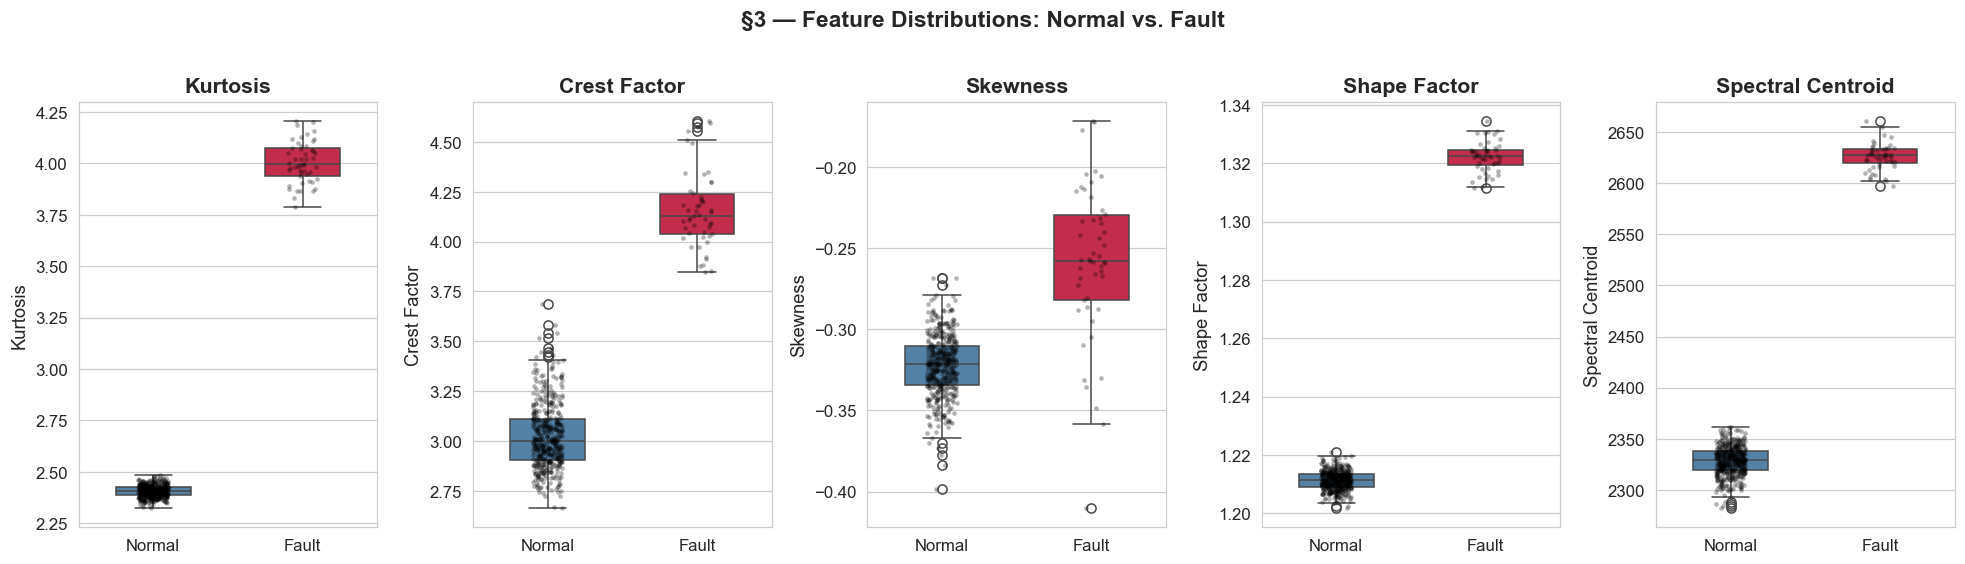

🔍 KEY INSIGHT: Kurtosis and Crest Factor show the clearest separation.
   These features are most discriminative for impulsive bearing faults.


In [5]:
# ============================================================
# §3a — Feature Distributions: Box plots + Strip plots
# ============================================================
fig, axes = plt.subplots(1, 5, figsize=(18, 5))
colors = {'Normal': 'steelblue', 'Fault': 'crimson'}

for i, feat in enumerate(feature_names):
    sns.boxplot(data=df, x='Label_str', y=feat, ax=axes[i], palette=colors, width=0.5)
    sns.stripplot(data=df, x='Label_str', y=feat, ax=axes[i], color='black', alpha=0.3, size=3, jitter=True)
    axes[i].set_title(feat, fontweight='bold')
    axes[i].set_xlabel('')

plt.suptitle('§3 — Feature Distributions: Normal vs. Fault', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("🔍 KEY INSIGHT: Kurtosis and Crest Factor show the clearest separation.")
print("   These features are most discriminative for impulsive bearing faults.")

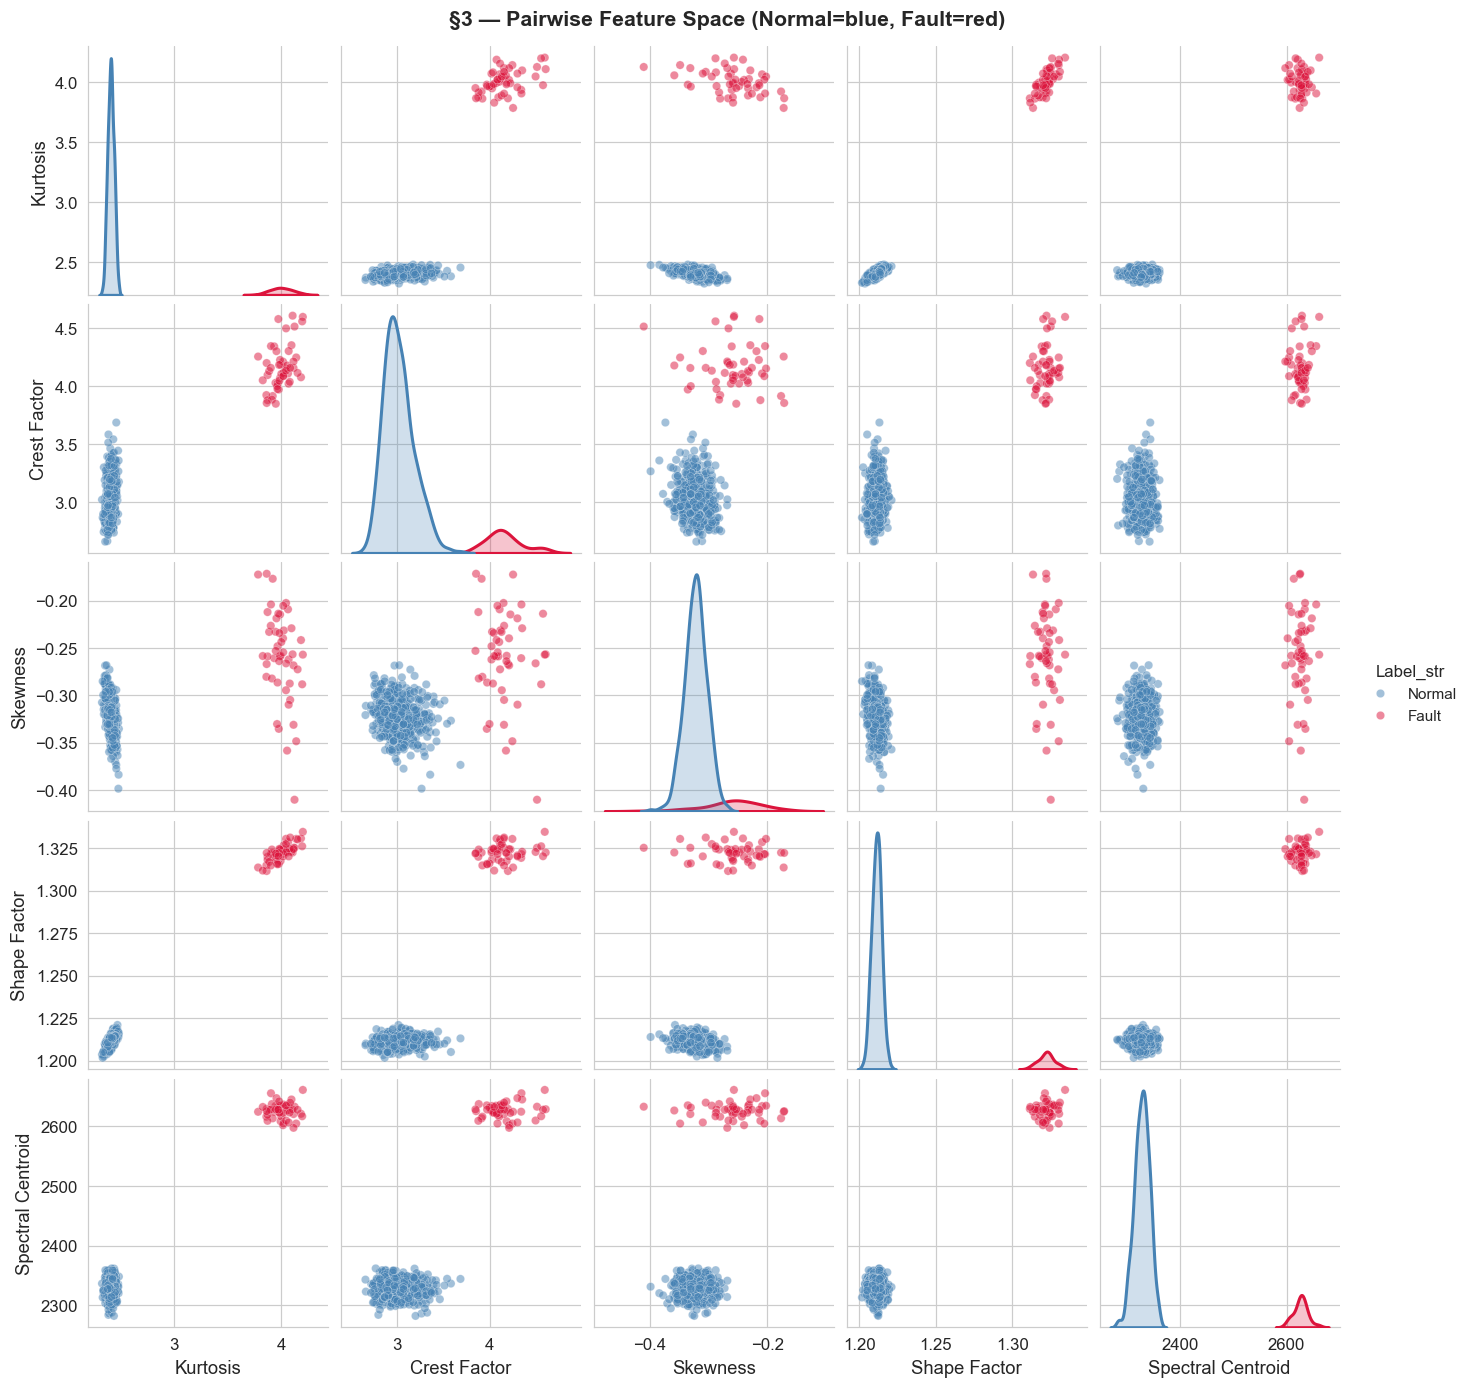

🔍 Look for clusters: Normal points form a dense cloud; faulty points are scattered outliers.


In [6]:
# ============================================================
# §3b — Pairwise Feature Scatter Matrix
# ============================================================
g = sns.pairplot(df, vars=feature_names, hue='Label_str',
                 palette=colors, diag_kind='kde',
                 plot_kws={'alpha': 0.5, 's': 30, 'edgecolor': 'white', 'linewidth': 0.3},
                 diag_kws={'linewidth': 2})
g.figure.suptitle('§3 — Pairwise Feature Space (Normal=blue, Fault=red)', y=1.01, fontsize=14, fontweight='bold')
plt.show()

print("🔍 Look for clusters: Normal points form a dense cloud; faulty points are scattered outliers.")

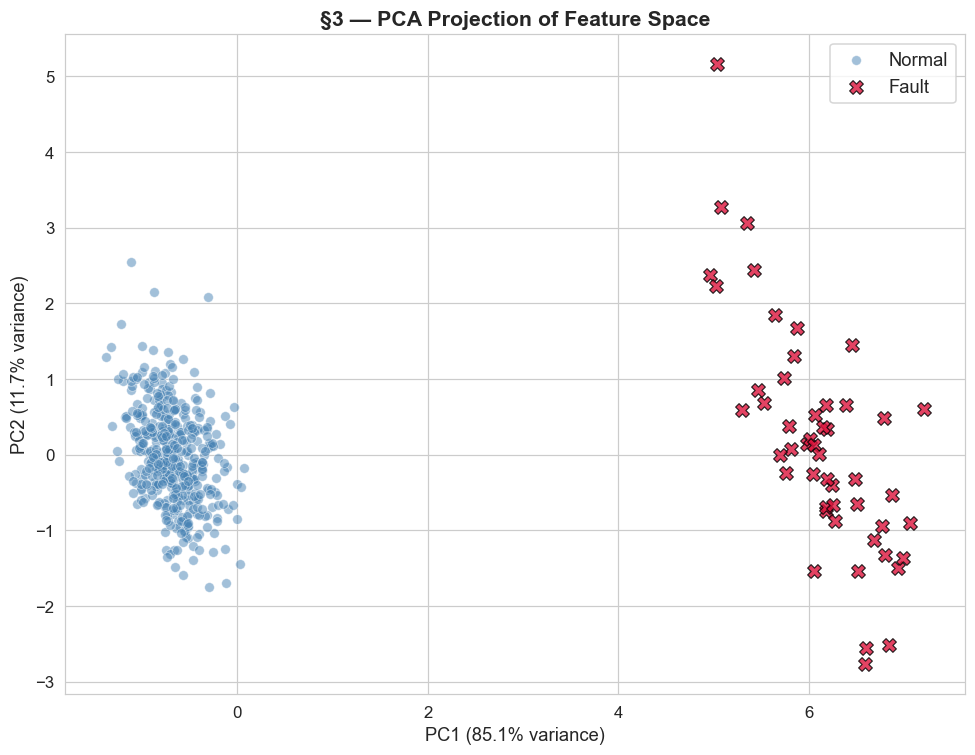

PCA explained variance: PC1=85.1%, PC2=11.7%
Total: 96.8%

🔍 Faulty samples (red X's) should lie away from the normal cluster.


In [7]:
# ============================================================
# §3c — PCA Projection to 2D (for later decision-boundary plots)
# ============================================================
X = df[feature_names].values
y_true = df['Label'].values  # 0 = normal, 1 = fault

# Standardize features (crucial for SVM and LOF)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# PCA for visualization
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

fig, ax = plt.subplots(figsize=(9, 7))
scatter_normal = ax.scatter(X_pca[y_true == 0, 0], X_pca[y_true == 0, 1],
                            c='steelblue', s=40, alpha=0.5, edgecolors='white', linewidth=0.5, label='Normal')
scatter_fault = ax.scatter(X_pca[y_true == 1, 0], X_pca[y_true == 1, 1],
                           c='crimson', s=80, alpha=0.8, edgecolors='black', linewidth=0.8, marker='X', label='Fault')
ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)')
ax.set_title('§3 — PCA Projection of Feature Space', fontweight='bold')
ax.legend(fontsize=12)
plt.tight_layout()
plt.show()

print(f"PCA explained variance: PC1={pca.explained_variance_ratio_[0]*100:.1f}%, PC2={pca.explained_variance_ratio_[1]*100:.1f}%")
print(f"Total: {sum(pca.explained_variance_ratio_)*100:.1f}%")
print("\n🔍 Faulty samples (red X's) should lie away from the normal cluster.")

---
## §4 — One-Class SVM (Deep Dive)

### How it works (intuition)
One-Class SVM (Schölkopf et al., 2001) learns a **decision boundary** that encloses the "normal" data in a high-dimensional feature space.

**Key idea:** Map data into a high-dimensional space using a **kernel function** (typically RBF: $K(x,x') = \exp(-\gamma \|x-x'\|^2)$), then find the **hyperplane** that maximally separates the data from the origin.

**The ν parameter** controls the trade-off:
- **ν** ∈ (0, 1] is an upper bound on the fraction of training samples that are allowed to be outliers, and a lower bound on the fraction of support vectors.
- Small ν → tight boundary (few outliers allowed) → risk missing faults
- Large ν → loose boundary (more outliers) → risk false alarms

**Decision function:** $f(x) = \text{sgn}\left(\sum_i \alpha_i K(x, x_i) - \rho\right)$
- $f(x) = +1$ → inlier (normal)
- $f(x) = -1$ → outlier (anomaly)

### When to use One-Class SVM
✅ Small to medium datasets (kernel computation is $O(n^2)$ to $O(n^3)$)  
✅ When you have ONLY normal training data (novelty detection)  
✅ When the boundary between normal/abnormal is complex & non-linear  
⚠️ Sensitive to the choice of kernel and γ  
⚠️ Does not scale well to very large datasets

In [8]:
# ============================================================
# §4a — Train One-Class SVM
# ============================================================

# For anomaly detection, we use contamination ≈ known fault ratio
nu_param = 0.10  # ≈ expected fraction of anomalies

ocsvm = OneClassSVM(kernel='rbf', gamma='scale', nu=nu_param)
ocsvm.fit(X_scaled)

# Predict: +1 = normal (inlier), -1 = anomaly (outlier)
y_pred_ocsvm = ocsvm.predict(X_scaled)

# Convert to our convention: 0 = normal, 1 = fault
y_pred_ocsvm_binary = (y_pred_ocsvm == -1).astype(int)

# Decision function scores (more negative = more anomalous)
scores_ocsvm = ocsvm.decision_function(X_scaled)

print("=== One-Class SVM Results ===")
print(f"ν (nu) = {nu_param}")
print(f"Kernel = RBF, γ = 'scale' → {ocsvm._gamma:.4f}")
print(f"Support vectors: {ocsvm.support_vectors_.shape[0]} / {X_scaled.shape[0]} samples")
print(f"\nPredicted Normal: {np.sum(y_pred_ocsvm_binary == 0)}")
print(f"Predicted Fault:  {np.sum(y_pred_ocsvm_binary == 1)}")
print(f"\n{classification_report(y_true, y_pred_ocsvm_binary, target_names=['Normal', 'Fault'])}")

=== One-Class SVM Results ===
ν (nu) = 0.1
Kernel = RBF, γ = 'scale' → 0.2000
Support vectors: 54 / 500 samples

Predicted Normal: 449
Predicted Fault:  51

              precision    recall  f1-score   support

      Normal       0.95      0.95      0.95       450
       Fault       0.53      0.54      0.53        50

    accuracy                           0.91       500
   macro avg       0.74      0.74      0.74       500
weighted avg       0.91      0.91      0.91       500



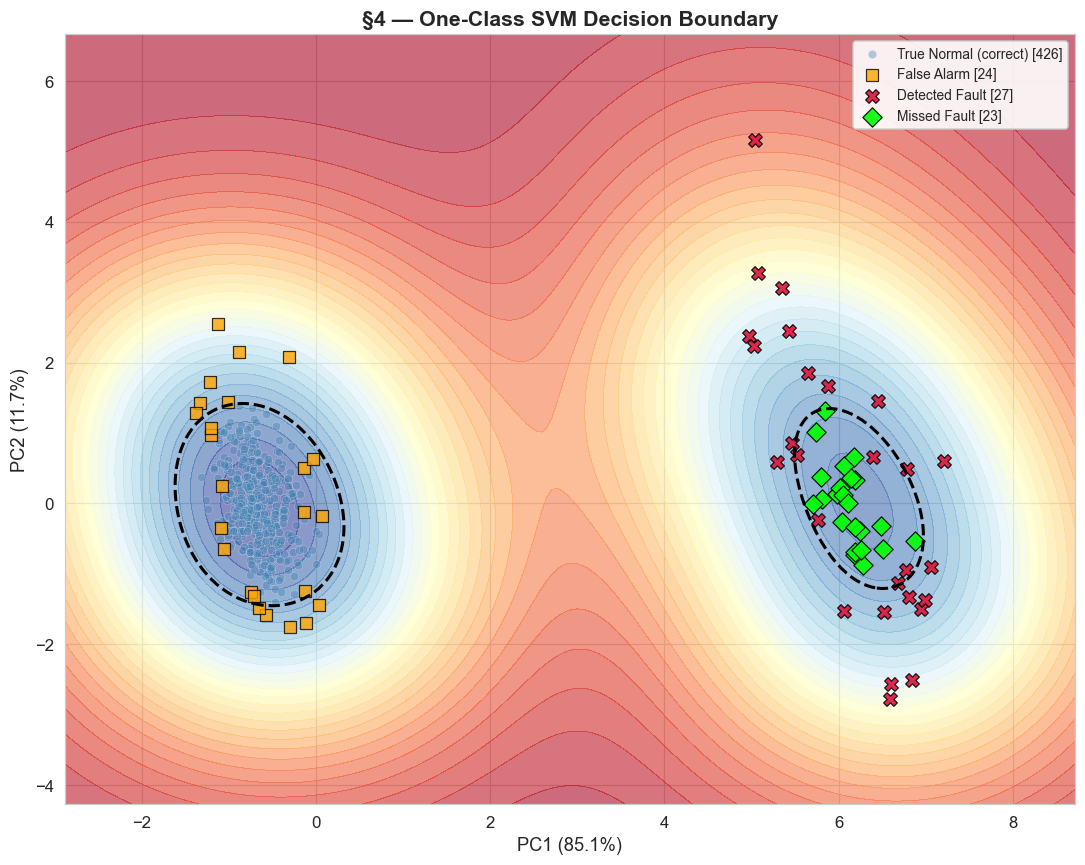

🔍 The BLACK DASHED LINE is the learned decision boundary.
   Points INSIDE (blue region) are classified as normal.
   Points OUTSIDE (red region) are classified as anomalous.


In [9]:
# ============================================================
# §4b — Visualize One-Class SVM Decision Boundary in PCA Space
# ============================================================

def plot_decision_boundary_pca(model, X_pca, y_true, y_pred, scores, title, ax=None):
    """Plot decision boundary of an anomaly detector in 2D PCA space."""
    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 8))
    
    # Create mesh grid
    margin = 1.5
    x_min, x_max = X_pca[:, 0].min() - margin, X_pca[:, 0].max() + margin
    y_min, y_max = X_pca[:, 1].min() - margin, X_pca[:, 1].max() + margin
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                         np.linspace(y_min, y_max, 200))
    
    # Project mesh back to original space for prediction
    mesh_pca = np.c_[xx.ravel(), yy.ravel()]
    mesh_original = pca.inverse_transform(mesh_pca)
    
    # Get decision scores on mesh
    if hasattr(model, 'decision_function'):
        Z = model.decision_function(mesh_original)
    else:
        Z = model.score_samples(mesh_original)
    Z = Z.reshape(xx.shape)
    
    # Plot decision regions
    ax.contourf(xx, yy, Z, levels=np.linspace(Z.min(), Z.max(), 30), cmap='RdYlBu', alpha=0.6)
    ax.contour(xx, yy, Z, levels=[0], colors='black', linewidths=2, linestyles='--')
    
    # Plot data points
    # True normals predicted normal
    mask_tn = (y_true == 0) & (y_pred == 0)
    ax.scatter(X_pca[mask_tn, 0], X_pca[mask_tn, 1], c='steelblue', s=30, alpha=0.4,
               edgecolors='white', linewidth=0.3, label=f'True Normal (correct) [{mask_tn.sum()}]')
    
    # True normals predicted fault (false positive)
    mask_fp = (y_true == 0) & (y_pred == 1)
    ax.scatter(X_pca[mask_fp, 0], X_pca[mask_fp, 1], c='orange', s=60, alpha=0.8,
               edgecolors='black', linewidth=0.8, marker='s', label=f'False Alarm [{mask_fp.sum()}]')
    
    # True faults predicted fault (true positive)
    mask_tp = (y_true == 1) & (y_pred == 1)
    ax.scatter(X_pca[mask_tp, 0], X_pca[mask_tp, 1], c='crimson', s=80, alpha=0.9,
               edgecolors='black', linewidth=0.8, marker='X', label=f'Detected Fault [{mask_tp.sum()}]')
    
    # True faults predicted normal (false negative — MISSED!)
    mask_fn = (y_true == 1) & (y_pred == 0)
    ax.scatter(X_pca[mask_fn, 0], X_pca[mask_fn, 1], c='lime', s=80, alpha=0.9,
               edgecolors='black', linewidth=0.8, marker='D', label=f'Missed Fault [{mask_fn.sum()}]')
    
    ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
    ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
    ax.set_title(title, fontweight='bold', fontsize=14)
    ax.legend(loc='best', fontsize=9, framealpha=0.9)
    return ax

fig, ax = plt.subplots(figsize=(10, 8))
plot_decision_boundary_pca(ocsvm, X_pca, y_true, y_pred_ocsvm_binary, scores_ocsvm,
                           '§4 — One-Class SVM Decision Boundary', ax)
plt.tight_layout()
plt.show()

print("🔍 The BLACK DASHED LINE is the learned decision boundary.")
print("   Points INSIDE (blue region) are classified as normal.")
print("   Points OUTSIDE (red region) are classified as anomalous.")

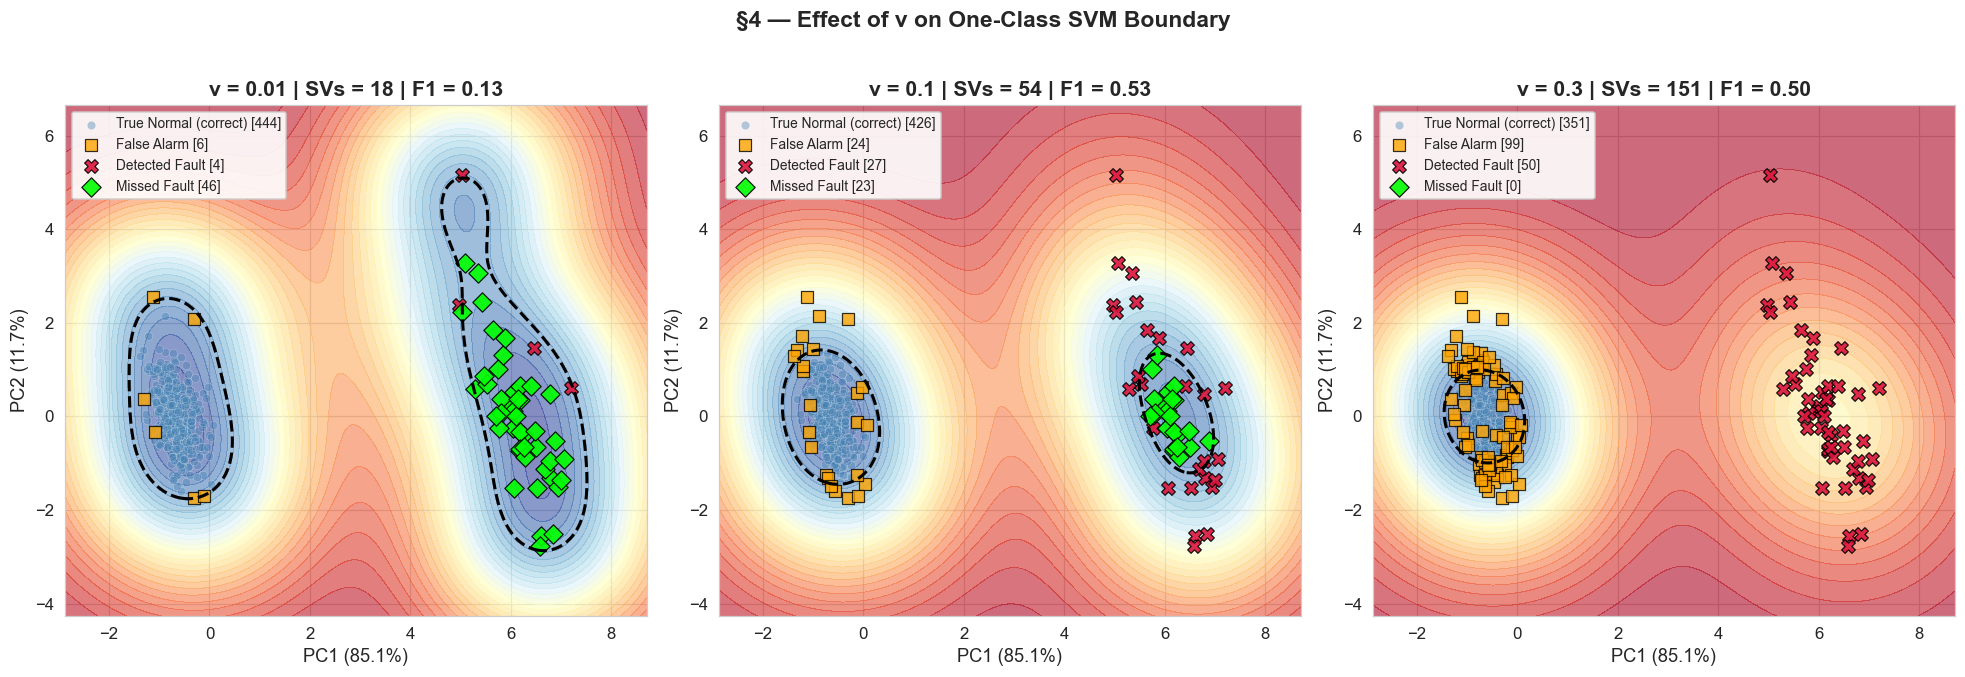

🔍 EXPERIMENT WITH ν:
   ν=0.01 → Very tight boundary, almost no outliers allowed
   ν=0.10 → Balanced — roughly matches our 10% fault rate
   ν=0.30 → Very loose — too many false alarms


In [10]:
# ============================================================
# §4c — Understanding ν: How it changes the boundary
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for i, nu in enumerate([0.01, 0.10, 0.30]):
    model = OneClassSVM(kernel='rbf', gamma='scale', nu=nu)
    model.fit(X_scaled)
    y_pred = (model.predict(X_scaled) == -1).astype(int)
    scores = model.decision_function(X_scaled)
    
    n_sv = model.support_vectors_.shape[0]
    f1 = f1_score(y_true, y_pred)
    
    plot_decision_boundary_pca(model, X_pca, y_true, y_pred, scores,
                               f'ν = {nu} | SVs = {n_sv} | F1 = {f1:.2f}', axes[i])

plt.suptitle('§4 — Effect of ν on One-Class SVM Boundary', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("🔍 EXPERIMENT WITH ν:")
print("   ν=0.01 → Very tight boundary, almost no outliers allowed")
print("   ν=0.10 → Balanced — roughly matches our 10% fault rate")
print("   ν=0.30 → Very loose — too many false alarms")

---
## §5 — Isolation Forest (Deep Dive)

### How it works (intuition)
Isolation Forest (Liu, Ting & Zhou, 2008) takes a fundamentally different approach: instead of modeling "normal", it directly **isolates anomalies**.

**Key idea:** Build an ensemble of random trees (iTrees). At each node, randomly pick a feature and a random split value. Anomalies, being "few and different", get **isolated in fewer splits** → they have **shorter path lengths** from root to leaf.

**The algorithm:**
1. Subsample the data (default: 256 samples)
2. Build a random tree: at each node, pick a random feature $q$ and random split $p \in [\min(q), \max(q)]$
3. Repeat to build a forest of $T$ trees (default: 100)
4. For each point, compute the **average path length** $E[h(x)]$ across all trees

**Anomaly score:** $s(x, m) = 2^{-E[h(x)] / c(m)}$
- $s \to 1$ → very likely anomaly (short paths)
- $s \to 0.5$ → no clear signal
- $s \to 0$ → very likely normal (long paths)

Where $c(m) = 2H(m-1) - 2(m-1)/n$ is the average path length in a BST (normalization factor).

### Key parameter: `contamination`
- Tells the model what fraction of the data is expected to be anomalous
- Used to set the threshold on the anomaly score
- Similar role to ν in One-Class SVM

### When to use Isolation Forest
✅ Large datasets (linear time complexity $O(n \cdot T)$)  
✅ High-dimensional data (handles irrelevant features)  
✅ No assumptions about data distribution  
✅ Works even without anomalies in training data  
⚠️ Can struggle with "local" anomalies in dense regions (→ use Extended IF)

In [ ]:
# ============================================================
# §5a — Train Isolation Forest
# ============================================================

# Initialize Isolation Forest model
# n_estimators=200: Build 200 random isolation trees for stable anomaly scoring
# contamination=0.10: Expect ~10% of data points to be anomalies (sets decision threshold)
# max_samples='auto': Use min(256, n_samples) subsampling per tree (default behavior)
# random_state=SEED: Fix random seed (42) for reproducible results across runs
iforest = IsolationForest(
    n_estimators=200,
    contamination=0.10,
    max_samples='auto',
    random_state=SEED
)

# Fit the model on the standardized feature matrix X_scaled (500 samples × 5 features)
# During fitting, each tree randomly subsamples data and recursively partitions it
# using random feature splits until each point is isolated (or max depth is reached)
iforest.fit(X_scaled)

# Predict anomaly labels for each sample
# Returns +1 for inliers (normal) and -1 for outliers (anomaly)
# The threshold is automatically set based on the contamination parameter (0.10)
y_pred_iforest = iforest.predict(X_scaled)

# Convert sklearn's convention (-1=outlier, +1=inlier) to our binary convention (1=fault, 0=normal)
# The comparison (y_pred_iforest == -1) produces a boolean array (True where outlier)
# .astype(int) converts True→1 (fault) and False→0 (normal)
y_pred_iforest_binary = (y_pred_iforest == -1).astype(int)

# Compute the continuous anomaly decision scores for each sample
# More negative values indicate more anomalous points (shorter average path length in the forest)
# More positive values indicate more normal points (longer average path length)
# These continuous scores are used later for ROC curves and threshold analysis
scores_iforest = iforest.decision_function(X_scaled)

# Print summary of Isolation Forest results
print("=== Isolation Forest Results ===")
print(f"n_estimators = 200, contamination = 0.10")

# Count how many samples were classified as normal vs. fault
print(f"\nPredicted Normal: {np.sum(y_pred_iforest_binary == 0)}")
print(f"Predicted Fault:  {np.sum(y_pred_iforest_binary == 1)}")

# Print detailed classification report comparing true labels (y_true) to predictions
# Includes precision, recall, F1-score, and support for each class (Normal and Fault)
print(f"\n{classification_report(y_true, y_pred_iforest_binary, target_names=['Normal', 'Fault'])}")

=== Isolation Forest Results ===
n_estimators = 200, contamination = 0.10

Predicted Normal: 450
Predicted Fault:  50

              precision    recall  f1-score   support

      Normal       0.99      0.99      0.99       450
       Fault       0.92      0.92      0.92        50

    accuracy                           0.98       500
   macro avg       0.96      0.96      0.96       500
weighted avg       0.98      0.98      0.98       500



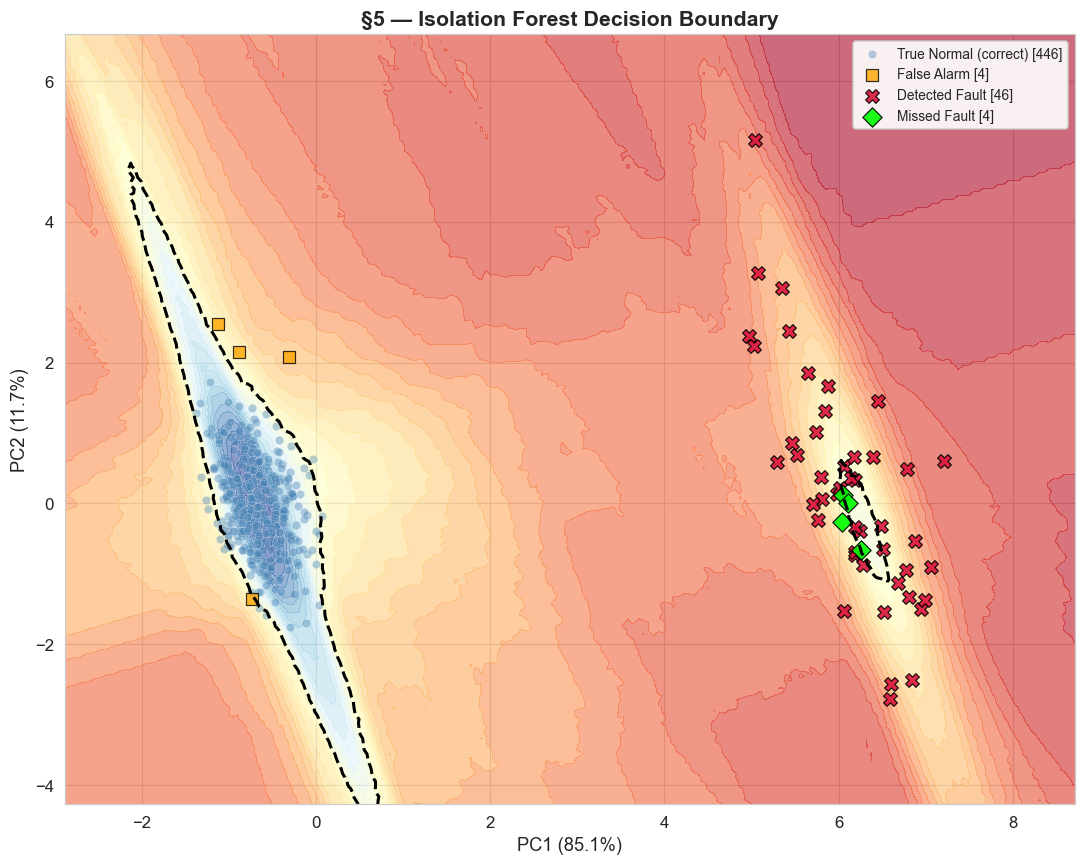

🔍 Compare with One-Class SVM: Isolation Forest's boundary is more 'blocky'
   because it uses axis-aligned splits (like a decision tree).


In [12]:
# ============================================================
# §5b — Visualize Isolation Forest Decision Boundary
# ============================================================

fig, ax = plt.subplots(figsize=(10, 8))
plot_decision_boundary_pca(iforest, X_pca, y_true, y_pred_iforest_binary, scores_iforest,
                           '§5 — Isolation Forest Decision Boundary', ax)
plt.tight_layout()
plt.show()

print("🔍 Compare with One-Class SVM: Isolation Forest's boundary is more 'blocky'")
print("   because it uses axis-aligned splits (like a decision tree).")

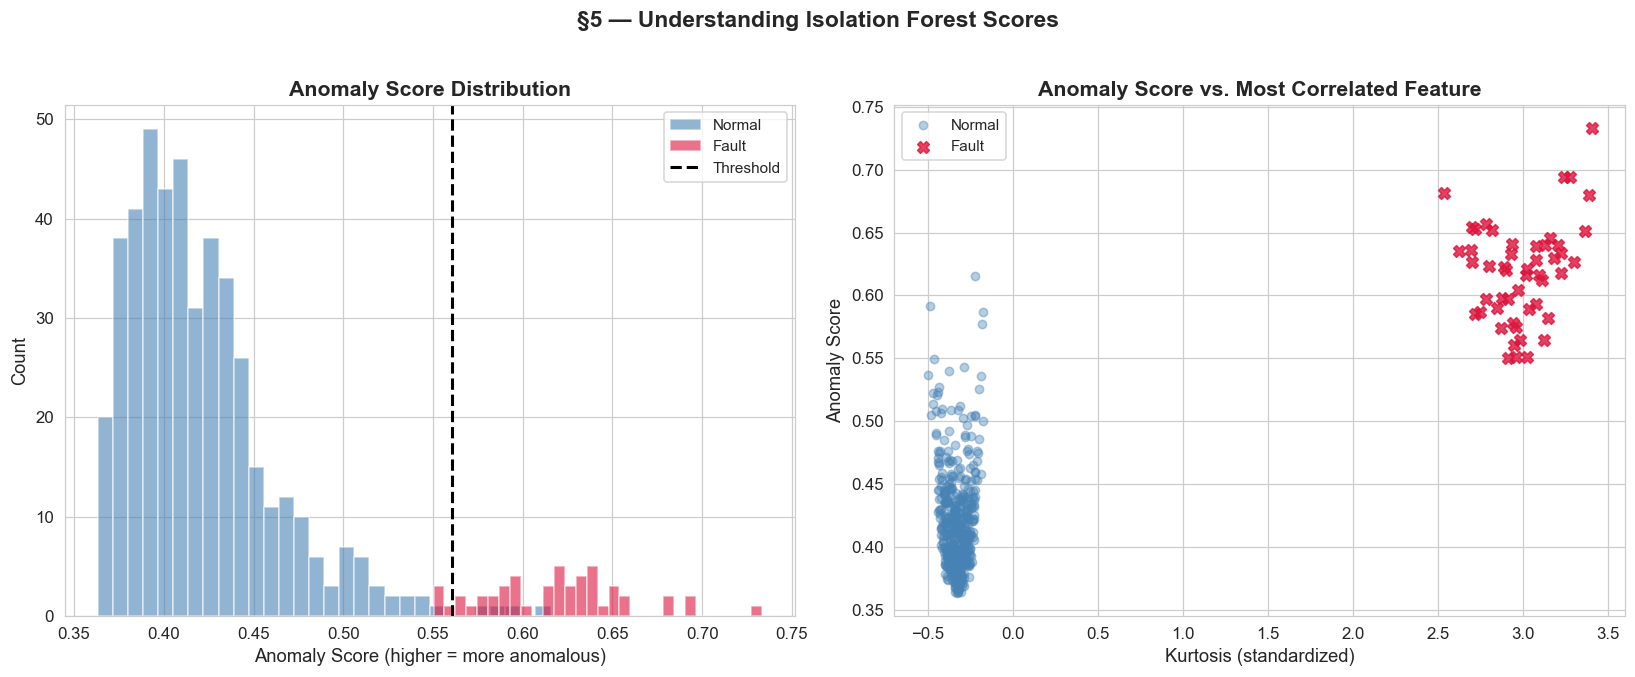

🔍 The histogram shows clear separation: faulty signals get HIGHER anomaly scores.
   The threshold (dashed line) sets the decision boundary between normal and fault.


In [13]:
# ============================================================
# §5c — Visualize Isolation: How path length separates anomalies
# ============================================================

# The anomaly score from sklearn is based on average path length
# score_samples returns the raw anomaly score (opposite sign of decision_function)
raw_scores = -iforest.score_samples(X_scaled)  # Higher = more anomalous

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Score distribution
for label, color, name in [(0, 'steelblue', 'Normal'), (1, 'crimson', 'Fault')]:
    axes[0].hist(raw_scores[y_true == label], bins=30, alpha=0.6, color=color, label=name, edgecolor='white')
axes[0].axvline(x=np.percentile(raw_scores, 100*(1-0.10)), color='black', linestyle='--', linewidth=2, label='Threshold')
axes[0].set_xlabel('Anomaly Score (higher = more anomalous)')
axes[0].set_ylabel('Count')
axes[0].set_title('Anomaly Score Distribution', fontweight='bold')
axes[0].legend()

# Score vs. each feature
feat_importance_idx = np.argsort([np.abs(np.corrcoef(raw_scores, X_scaled[:, i])[0, 1]) for i in range(5)])[::-1]
top_feat = feat_importance_idx[0]
axes[1].scatter(X_scaled[y_true == 0, top_feat], raw_scores[y_true == 0],
                c='steelblue', alpha=0.4, s=30, label='Normal')
axes[1].scatter(X_scaled[y_true == 1, top_feat], raw_scores[y_true == 1],
                c='crimson', alpha=0.8, s=60, marker='X', label='Fault')
axes[1].set_xlabel(f'{feature_names[top_feat]} (standardized)')
axes[1].set_ylabel('Anomaly Score')
axes[1].set_title(f'Anomaly Score vs. Most Correlated Feature', fontweight='bold')
axes[1].legend()

plt.suptitle('§5 — Understanding Isolation Forest Scores', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("🔍 The histogram shows clear separation: faulty signals get HIGHER anomaly scores.")
print("   The threshold (dashed line) sets the decision boundary between normal and fault.")

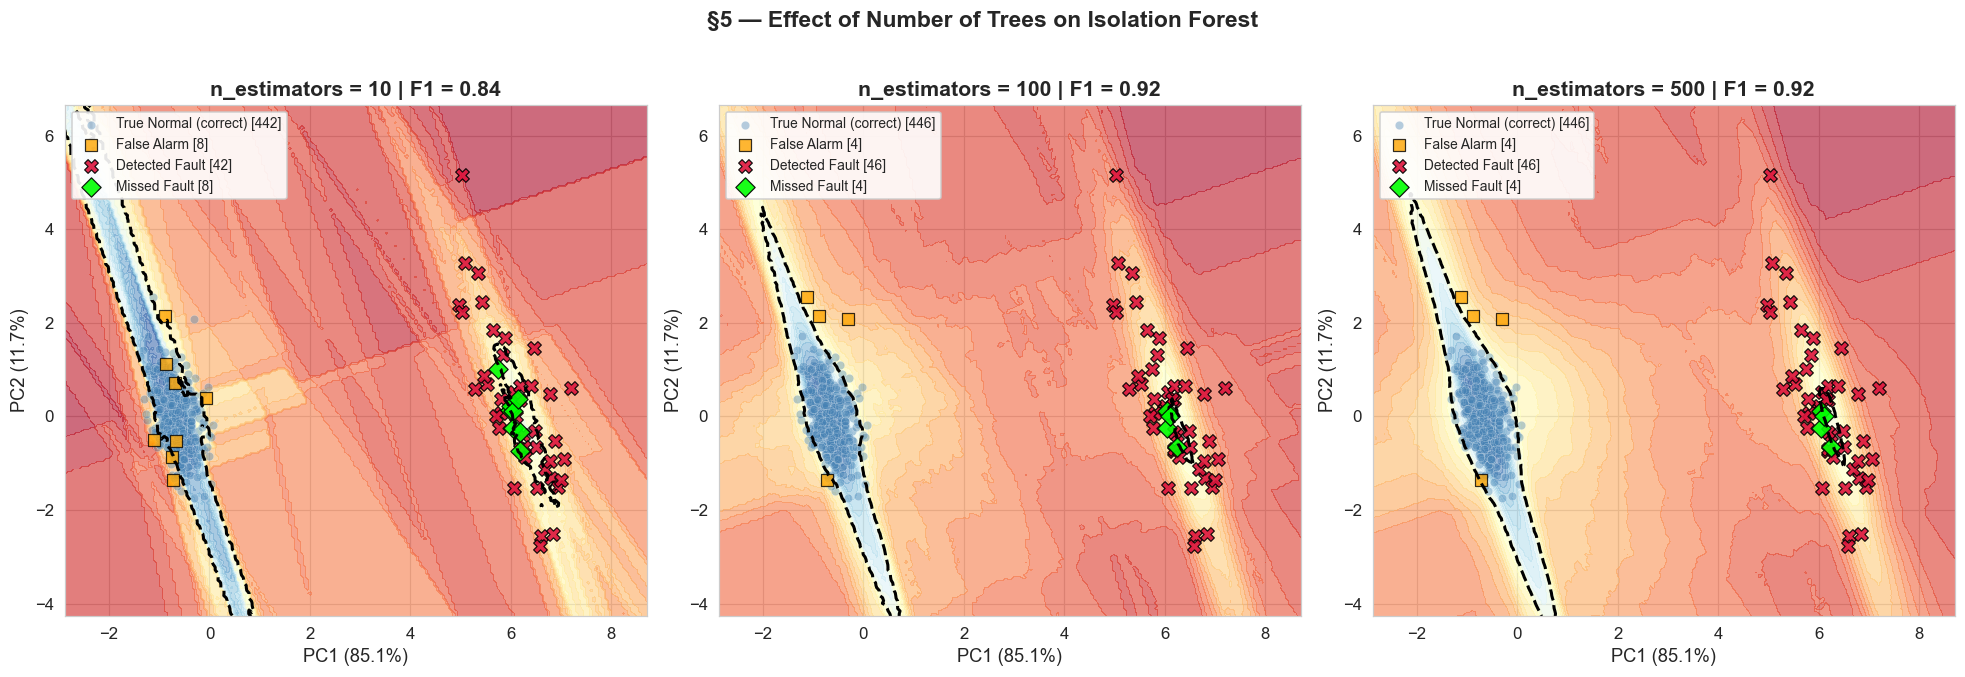

🔍 More trees → smoother, more stable decision boundary
   Too few trees → noisy, unstable boundaries


In [14]:
# ============================================================
# §5d — Effect of n_estimators on Isolation Forest
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for i, n_est in enumerate([10, 100, 500]):
    model = IsolationForest(n_estimators=n_est, contamination=0.10, random_state=SEED)
    model.fit(X_scaled)
    y_pred = (model.predict(X_scaled) == -1).astype(int)
    scores = model.decision_function(X_scaled)
    f1 = f1_score(y_true, y_pred)
    
    plot_decision_boundary_pca(model, X_pca, y_true, y_pred, scores,
                               f'n_estimators = {n_est} | F1 = {f1:.2f}', axes[i])

plt.suptitle('§5 — Effect of Number of Trees on Isolation Forest', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("🔍 More trees → smoother, more stable decision boundary")
print("   Too few trees → noisy, unstable boundaries")

---
## §6 — Local Outlier Factor (Deep Dive)

### How it works (intuition)
LOF (Breunig et al., 2000) measures the **local density** around each point relative to its neighbors. A point is anomalous if its local density is **significantly lower** than that of its neighbors.

**The algorithm (step by step):**

1. **k-distance**: For each point $p$, find the distance to its $k$-th nearest neighbor
2. **Reachability distance**: $\text{reach\_dist}_k(p, o) = \max(k\text{-dist}(o), \; d(p, o))$
   - This "smooths" distances: if $o$ is deep inside a cluster, its reachability distance from $p$ is at least $k$-dist($o$)
3. **Local Reachability Density (LRD)**: $\text{LRD}_k(p) = 1 \Big/ \frac{\sum_{o \in N_k(p)} \text{reach\_dist}_k(p, o)}{|N_k(p)|}$
   - Inverse of the average reachability distance to the $k$ nearest neighbors
4. **LOF score**: $\text{LOF}_k(p) = \frac{\sum_{o \in N_k(p)} \frac{\text{LRD}_k(o)}{\text{LRD}_k(p)}}{|N_k(p)|}$
   - Ratio of average neighbor density to the point's own density
   - $\text{LOF} \approx 1$ → similar density to neighbors (normal)
   - $\text{LOF} \gg 1$ → much lower density than neighbors (anomaly!)

### Key parameter: `n_neighbors` ($k$)
- Small $k$ → very local comparison (sensitive to noise)
- Large $k$ → more global comparison (may miss local anomalies)
- Rule of thumb: $k = 20$ works well in general

### When to use LOF
✅ When anomalies are "local" (e.g., normal in one region but anomalous in another)  
✅ When data has varying densities across regions  
✅ Small to medium datasets  
⚠️ Computational cost: $O(n^2)$ for distance computation  
⚠️ The `novelty=True` mode is needed for predicting on new data

In [15]:
# ============================================================
# §6a — Train Local Outlier Factor
# ============================================================

lof = LocalOutlierFactor(
    n_neighbors=20,
    contamination=0.10,
    novelty=False   # For outlier detection (fit_predict mode)
)

# LOF with novelty=False only has fit_predict
y_pred_lof = lof.fit_predict(X_scaled)
y_pred_lof_binary = (y_pred_lof == -1).astype(int)

# LOF scores (more negative = more anomalous)
scores_lof = lof.negative_outlier_factor_

print("=== Local Outlier Factor Results ===")
print(f"n_neighbors = 20, contamination = 0.10")
print(f"\nPredicted Normal: {np.sum(y_pred_lof_binary == 0)}")
print(f"Predicted Fault:  {np.sum(y_pred_lof_binary == 1)}")
print(f"\n{classification_report(y_true, y_pred_lof_binary, target_names=['Normal', 'Fault'])}")

=== Local Outlier Factor Results ===
n_neighbors = 20, contamination = 0.10

Predicted Normal: 450
Predicted Fault:  50

              precision    recall  f1-score   support

      Normal       0.92      0.92      0.92       450
       Fault       0.24      0.24      0.24        50

    accuracy                           0.85       500
   macro avg       0.58      0.58      0.58       500
weighted avg       0.85      0.85      0.85       500



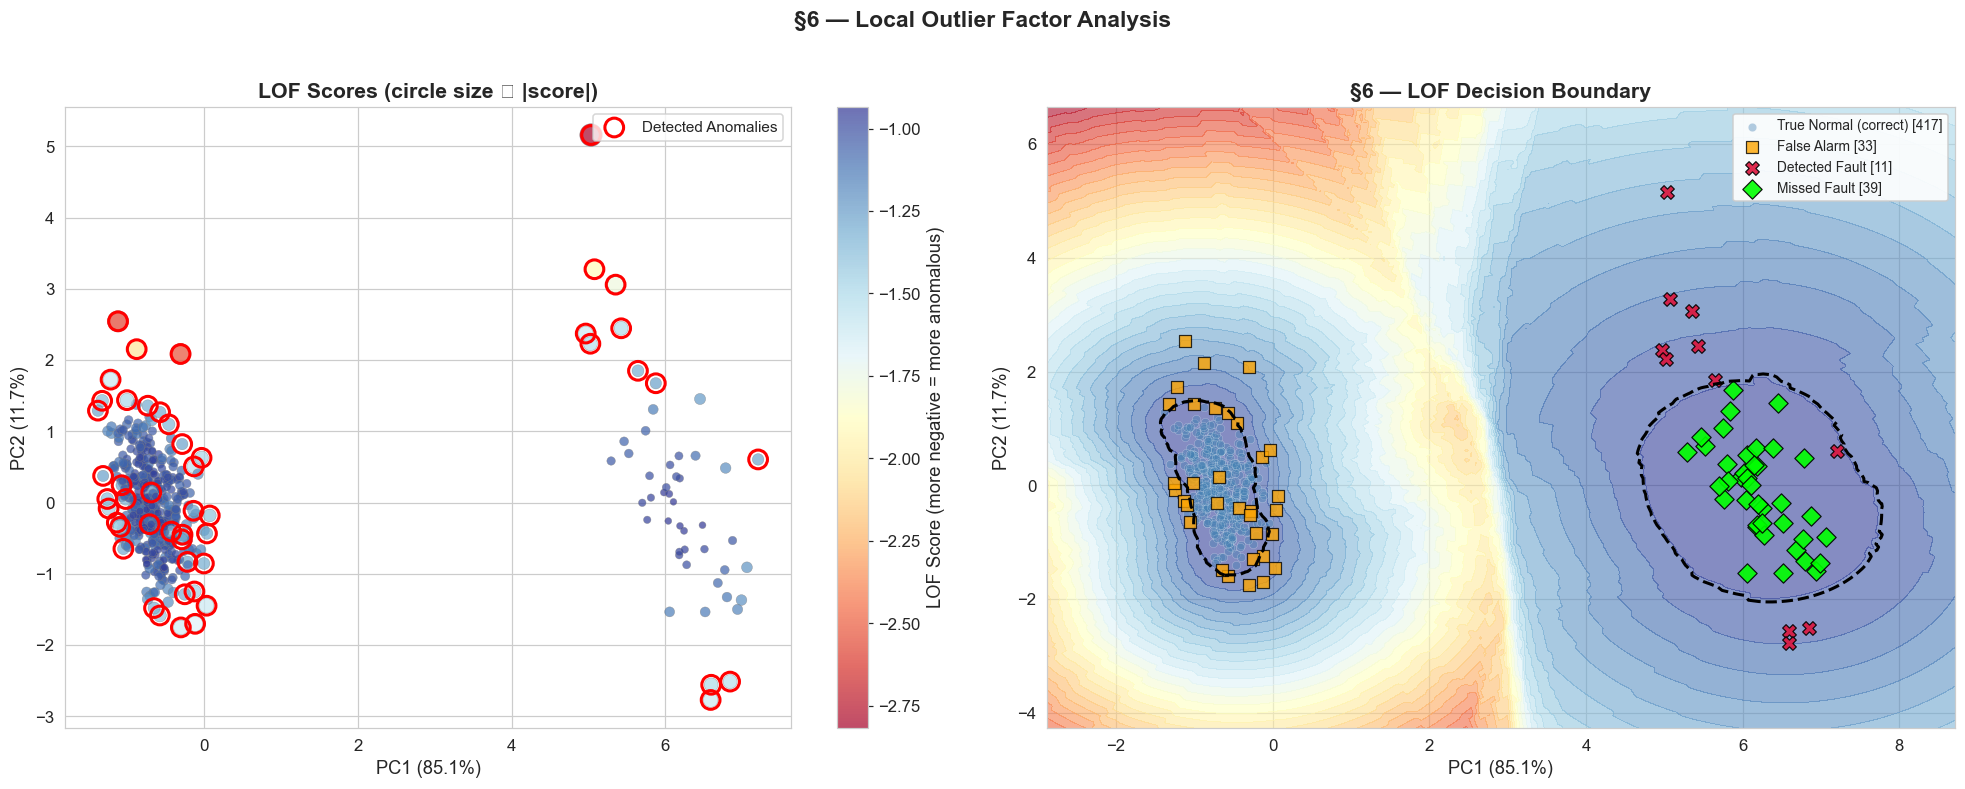

🔍 LEFT: Larger, redder circles = more anomalous according to LOF
   RIGHT: The decision boundary adapts to LOCAL density (unlike One-Class SVM)


In [16]:
# ============================================================
# §6b — Visualize LOF Scores and Decision Boundary
# ============================================================

# For LOF, we need novelty=True to get decision_function on new data
lof_novelty = LocalOutlierFactor(n_neighbors=20, contamination=0.10, novelty=True)
lof_novelty.fit(X_scaled)
scores_lof_novelty = lof_novelty.decision_function(X_scaled)
y_pred_lof_novelty_binary = (lof_novelty.predict(X_scaled) == -1).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# --- Left: LOF score visualization ---
# Size of points proportional to |LOF score|
lof_scores_abs = np.abs(scores_lof)
sizes = 20 + 200 * (lof_scores_abs - lof_scores_abs.min()) / (lof_scores_abs.max() - lof_scores_abs.min())

scatter = axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=scores_lof, cmap='RdYlBu',
                          s=sizes, alpha=0.7, edgecolors='gray', linewidth=0.3)
plt.colorbar(scatter, ax=axes[0], label='LOF Score (more negative = more anomalous)')

# Highlight detected anomalies
anomaly_mask = y_pred_lof_binary == 1
axes[0].scatter(X_pca[anomaly_mask, 0], X_pca[anomaly_mask, 1],
                facecolors='none', edgecolors='red', s=150, linewidth=2, label='Detected Anomalies')
axes[0].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
axes[0].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
axes[0].set_title('LOF Scores (circle size ∝ |score|)', fontweight='bold')
axes[0].legend(fontsize=10)

# --- Right: Decision boundary (using novelty=True model) ---
plot_decision_boundary_pca(lof_novelty, X_pca, y_true, y_pred_lof_novelty_binary,
                           scores_lof_novelty, '§6 — LOF Decision Boundary', axes[1])

plt.suptitle('§6 — Local Outlier Factor Analysis', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("🔍 LEFT: Larger, redder circles = more anomalous according to LOF")
print("   RIGHT: The decision boundary adapts to LOCAL density (unlike One-Class SVM)")

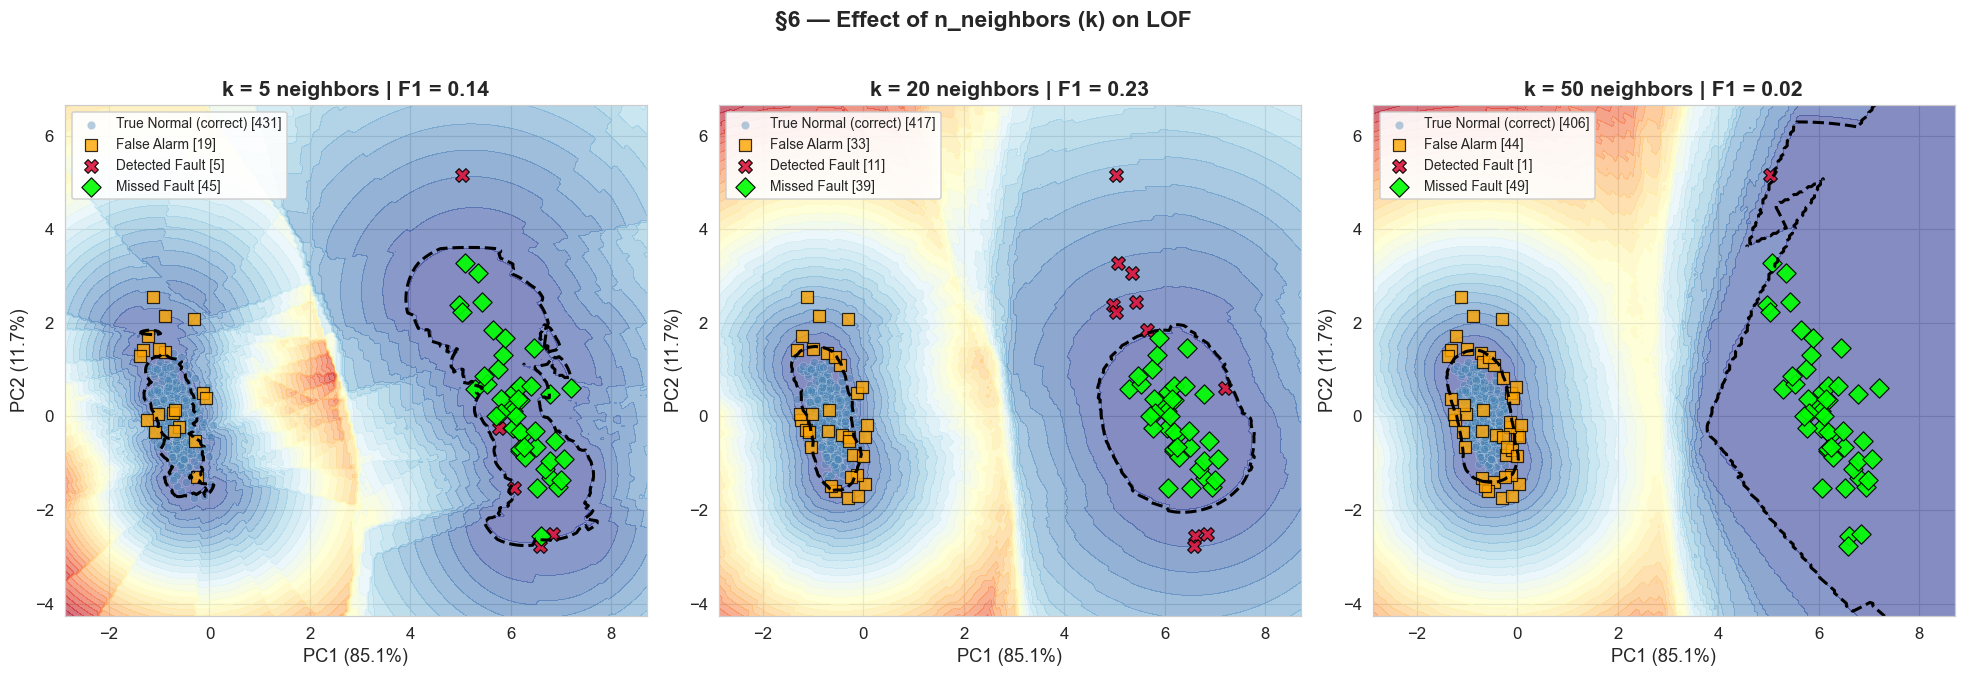

🔍 EXPERIMENT WITH k:
   k=5  → Very local: captures fine-grained density differences, but noisy
   k=20 → Balanced: standard choice, works well in most cases
   k=50 → More global: smoother boundary, may miss local anomalies


In [17]:
# ============================================================
# §6c — Effect of n_neighbors on LOF
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for i, k in enumerate([5, 20, 50]):
    model = LocalOutlierFactor(n_neighbors=k, contamination=0.10, novelty=True)
    model.fit(X_scaled)
    y_pred = (model.predict(X_scaled) == -1).astype(int)
    scores = model.decision_function(X_scaled)
    f1 = f1_score(y_true, y_pred)
    
    plot_decision_boundary_pca(model, X_pca, y_true, y_pred, scores,
                               f'k = {k} neighbors | F1 = {f1:.2f}', axes[i])

plt.suptitle('§6 — Effect of n_neighbors (k) on LOF', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("🔍 EXPERIMENT WITH k:")
print("   k=5  → Very local: captures fine-grained density differences, but noisy")
print("   k=20 → Balanced: standard choice, works well in most cases")
print("   k=50 → More global: smoother boundary, may miss local anomalies")

---
## §7 — Head-to-Head Model Comparison

### Standard ML Metrics for Anomaly Detection

For anomaly detection, the choice of metric matters a lot because the classes are **imbalanced** (few anomalies, many normals):

| Metric | Formula | What it tells you |
|---|---|---|
| **Accuracy** | $\frac{TP + TN}{TP + TN + FP + FN}$ | Overall correctness — misleading for imbalanced data! |
| **Precision** | $\frac{TP}{TP + FP}$ | Of all detected "faults", how many are real faults? (Low FP is important for avoiding unnecessary shutdowns) |
| **Recall (Sensitivity)** | $\frac{TP}{TP + FN}$ | Of all real faults, how many did we catch? (High recall = don't miss any faults) |
| **F1-Score** | $\frac{2 \cdot P \cdot R}{P + R}$ | Harmonic mean of Precision and Recall — good single metric |
| **ROC-AUC** | Area under ROC curve | Ability to rank anomalies higher than normals across ALL thresholds |
| **PR-AUC** | Area under PR curve | Better than ROC-AUC for imbalanced data — focuses on the positive (fault) class |

> **In safety-critical applications (like bearing monitoring): Recall > Precision**  
> Missing a real fault (False Negative) is far worse than a false alarm (False Positive).

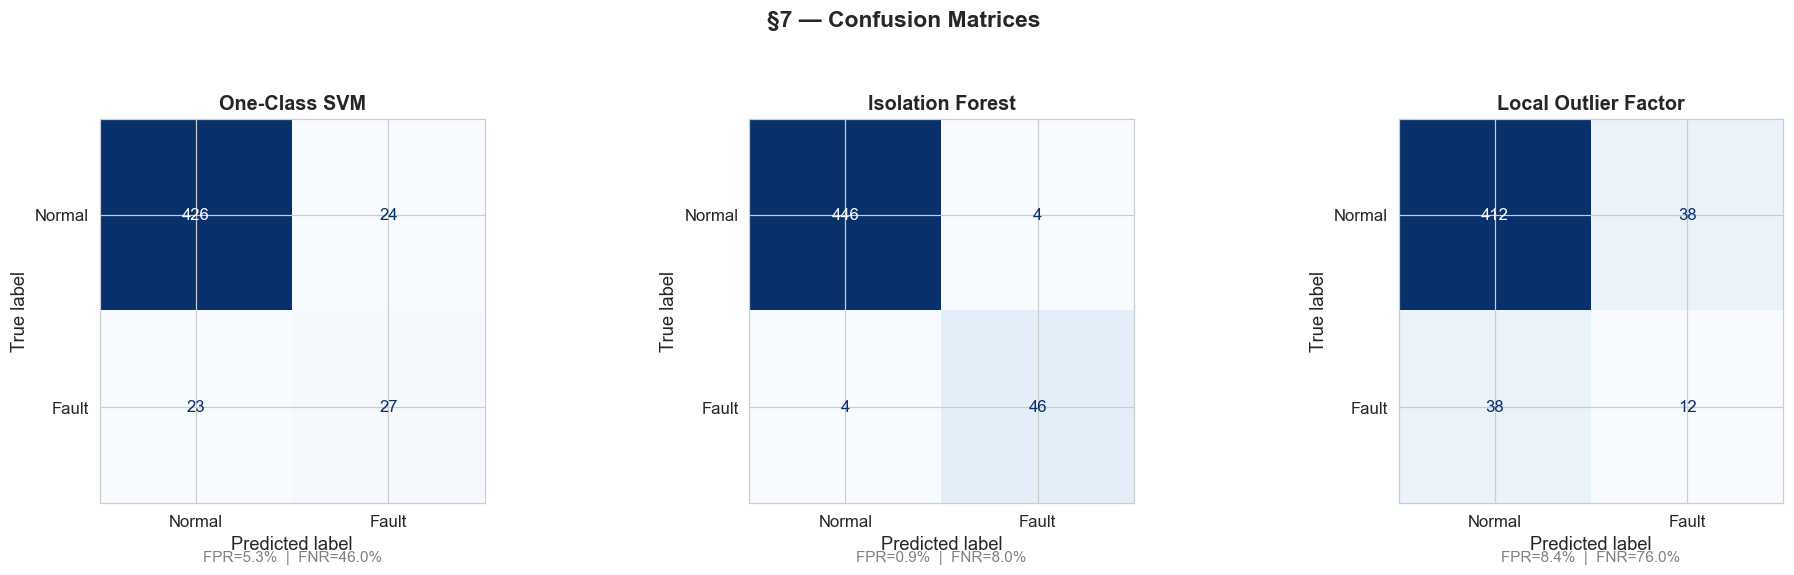

🔍 KEY CELLS TO WATCH:
   Top-right (FP): False alarms — model says 'fault' but it's normal
   Bottom-left (FN): Missed faults — model says 'normal' but it's a fault (DANGEROUS!)


In [18]:
# ============================================================
# §7a — Confusion Matrices Side-by-Side
# ============================================================

models = {
    'One-Class SVM': y_pred_ocsvm_binary,
    'Isolation Forest': y_pred_iforest_binary,
    'Local Outlier Factor': y_pred_lof_binary,
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, (name, y_pred) in enumerate(models.items()):
    cm = confusion_matrix(y_true, y_pred)
    disp = ConfusionMatrixDisplay(cm, display_labels=['Normal', 'Fault'])
    disp.plot(ax=axes[i], cmap='Blues', colorbar=False)
    axes[i].set_title(f'{name}', fontweight='bold', fontsize=13)
    
    # Annotate with rates
    tn, fp, fn, tp = cm.ravel()
    axes[i].text(0.5, -0.15, f'FPR={fp/(fp+tn)*100:.1f}%  |  FNR={fn/(fn+tp)*100:.1f}%',
                 transform=axes[i].transAxes, ha='center', fontsize=10, color='gray')

plt.suptitle('§7 — Confusion Matrices', fontsize=15, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()

print("🔍 KEY CELLS TO WATCH:")
print("   Top-right (FP): False alarms — model says 'fault' but it's normal")
print("   Bottom-left (FN): Missed faults — model says 'normal' but it's a fault (DANGEROUS!)")

In [19]:
# ============================================================
# §7b — Metrics Summary Table
# ============================================================

metrics_data = []
for name, y_pred in models.items():
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    fpr = fp / (fp + tn)
    fnr = fn / (fn + tp)
    
    metrics_data.append({
        'Model': name,
        'Accuracy': f'{acc:.3f}',
        'Precision': f'{prec:.3f}',
        'Recall': f'{rec:.3f}',
        'F1-Score': f'{f1:.3f}',
        'FPR': f'{fpr:.3f}',
        'FNR (Miss Rate)': f'{fnr:.3f}',
        'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn
    })

metrics_df = pd.DataFrame(metrics_data)
print("=" * 80)
print("§7 — MODEL COMPARISON SUMMARY")
print("=" * 80)
print(metrics_df.to_string(index=False))
print("=" * 80)
print("\n⚠️  In safety-critical settings, prioritize LOW FNR (Miss Rate)!")
print("    A missed fault can lead to catastrophic equipment failure.")

§7 — MODEL COMPARISON SUMMARY
               Model Accuracy Precision Recall F1-Score   FPR FNR (Miss Rate)  TP  FP  FN  TN
       One-Class SVM    0.906     0.529  0.540    0.535 0.053           0.460  27  24  23 426
    Isolation Forest    0.984     0.920  0.920    0.920 0.009           0.080  46   4   4 446
Local Outlier Factor    0.848     0.240  0.240    0.240 0.084           0.760  12  38  38 412

⚠️  In safety-critical settings, prioritize LOW FNR (Miss Rate)!
    A missed fault can lead to catastrophic equipment failure.


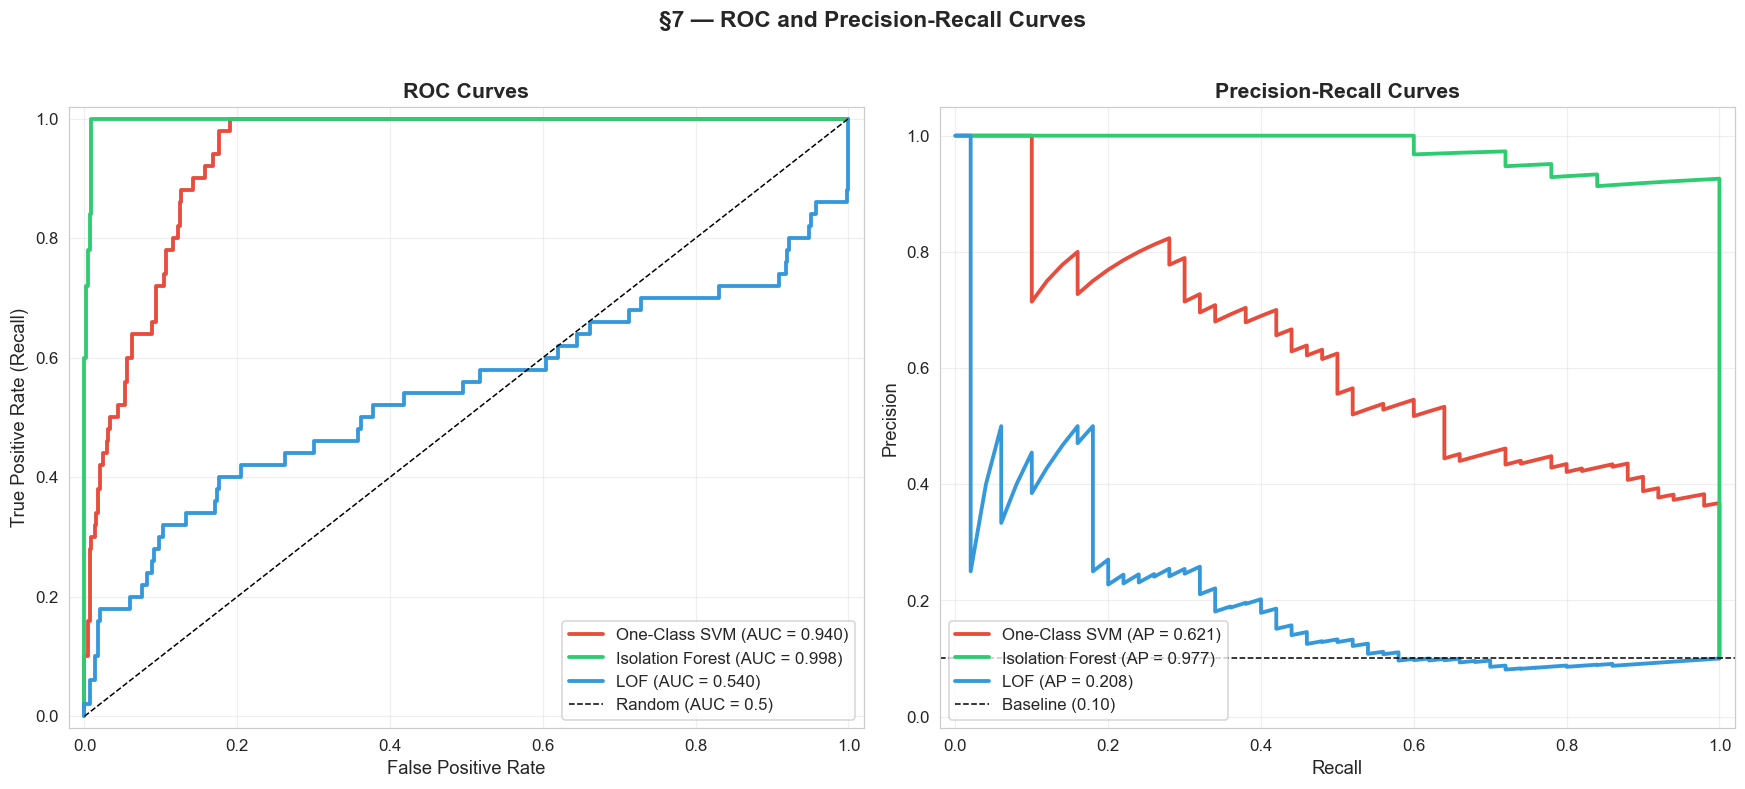

🔍 ROC CURVE: Higher AUC = better model at ALL thresholds
   PR CURVE: More informative for imbalanced data
   The PR curve penalizes false positives more harshly than ROC.


In [20]:
# ============================================================
# §7c — ROC Curves (Receiver Operating Characteristic)
# ============================================================
# For ROC, we need continuous scores (not binary predictions)
# More negative scores = more anomalous for all three models

score_dict = {
    'One-Class SVM': -scores_ocsvm,           # Negate: higher = more anomalous
    'Isolation Forest': -scores_iforest,
    'LOF': -scores_lof,                        # negative_outlier_factor_ (already negative for outliers)
}

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
colors_models = ['#e74c3c', '#2ecc71', '#3498db']

# --- ROC Curves ---
for (name, scores), color in zip(score_dict.items(), colors_models):
    fpr_arr, tpr_arr, _ = roc_curve(y_true, scores)
    roc_auc = auc(fpr_arr, tpr_arr)
    axes[0].plot(fpr_arr, tpr_arr, color=color, linewidth=2.5, label=f'{name} (AUC = {roc_auc:.3f})')

axes[0].plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random (AUC = 0.5)')
axes[0].set_xlabel('False Positive Rate', fontsize=12)
axes[0].set_ylabel('True Positive Rate (Recall)', fontsize=12)
axes[0].set_title('ROC Curves', fontweight='bold', fontsize=14)
axes[0].legend(fontsize=11)
axes[0].set_xlim([-0.02, 1.02])
axes[0].set_ylim([-0.02, 1.02])
axes[0].grid(True, alpha=0.3)

# --- Precision-Recall Curves ---
for (name, scores), color in zip(score_dict.items(), colors_models):
    prec_arr, rec_arr, _ = precision_recall_curve(y_true, scores)
    pr_auc = average_precision_score(y_true, scores)
    axes[1].plot(rec_arr, prec_arr, color=color, linewidth=2.5, label=f'{name} (AP = {pr_auc:.3f})')

baseline = np.sum(y_true == 1) / len(y_true)
axes[1].axhline(y=baseline, color='k', linestyle='--', linewidth=1, label=f'Baseline ({baseline:.2f})')
axes[1].set_xlabel('Recall', fontsize=12)
axes[1].set_ylabel('Precision', fontsize=12)
axes[1].set_title('Precision-Recall Curves', fontweight='bold', fontsize=14)
axes[1].legend(fontsize=11)
axes[1].set_xlim([-0.02, 1.02])
axes[1].set_ylim([-0.02, 1.05])
axes[1].grid(True, alpha=0.3)

plt.suptitle('§7 — ROC and Precision-Recall Curves', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("🔍 ROC CURVE: Higher AUC = better model at ALL thresholds")
print("   PR CURVE: More informative for imbalanced data")
print("   The PR curve penalizes false positives more harshly than ROC.")

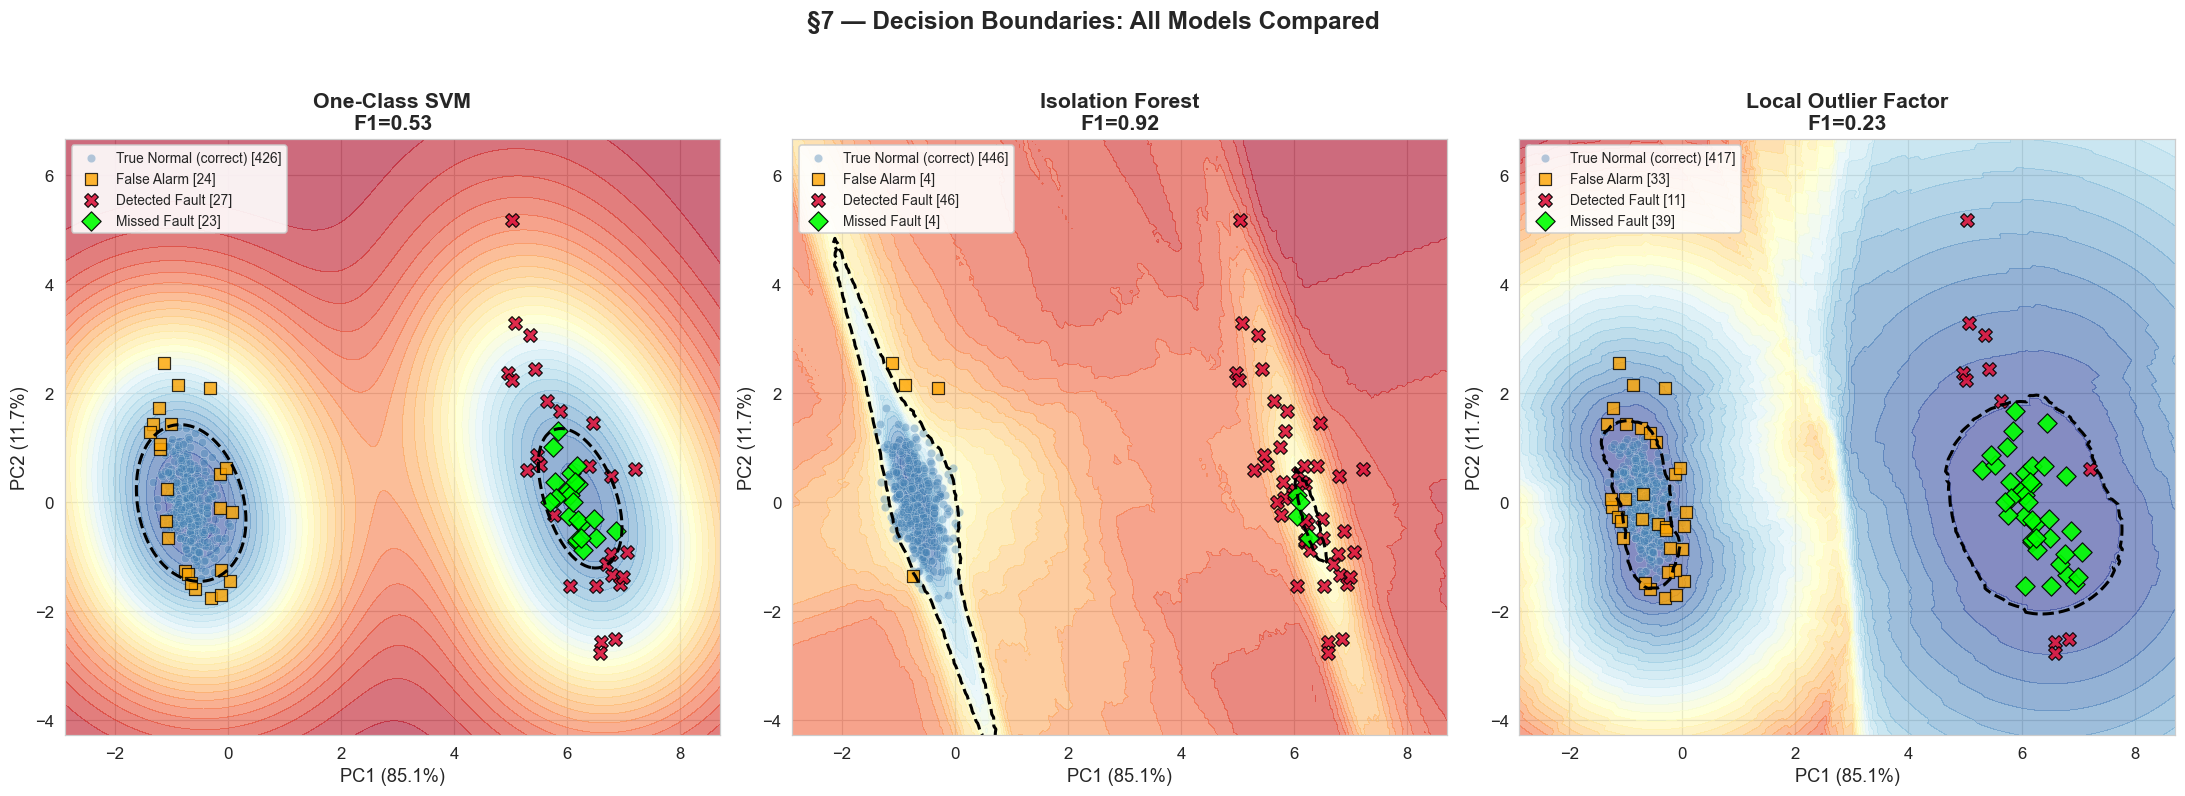

🔍 COMPARE THE SHAPES:
   SVM → Smooth, kernel-shaped boundary (elliptical for RBF)
   IF  → Rectangular/blocky (axis-aligned splits)
   LOF → Follows local density contours (most adaptive)


In [21]:
# ============================================================
# §7d — All Three Decision Boundaries Side-by-Side
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(20, 7))

# One-Class SVM
plot_decision_boundary_pca(ocsvm, X_pca, y_true, y_pred_ocsvm_binary, scores_ocsvm,
                           f'One-Class SVM\nF1={f1_score(y_true, y_pred_ocsvm_binary):.2f}', axes[0])

# Isolation Forest
plot_decision_boundary_pca(iforest, X_pca, y_true, y_pred_iforest_binary, scores_iforest,
                           f'Isolation Forest\nF1={f1_score(y_true, y_pred_iforest_binary):.2f}', axes[1])

# LOF (novelty mode)
plot_decision_boundary_pca(lof_novelty, X_pca, y_true, y_pred_lof_novelty_binary, scores_lof_novelty,
                           f'Local Outlier Factor\nF1={f1_score(y_true, y_pred_lof_novelty_binary):.2f}', axes[2])

plt.suptitle('§7 — Decision Boundaries: All Models Compared', fontsize=16, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

print("🔍 COMPARE THE SHAPES:")
print("   SVM → Smooth, kernel-shaped boundary (elliptical for RBF)")
print("   IF  → Rectangular/blocky (axis-aligned splits)")
print("   LOF → Follows local density contours (most adaptive)")

---
## §8 — Hyperparameter Sensitivity & Interactive Exploration

How sensitive are the models to their key hyperparameters? This is critical for real-world deployment. Let's sweep each model's main parameter and watch how performance changes.

**Key parameters:**
- **One-Class SVM:** `nu` (ν) — fraction of outliers / support vectors
- **Isolation Forest:** `contamination` — expected anomaly fraction
- **LOF:** `n_neighbors` ($k$) — neighborhood size for density estimation

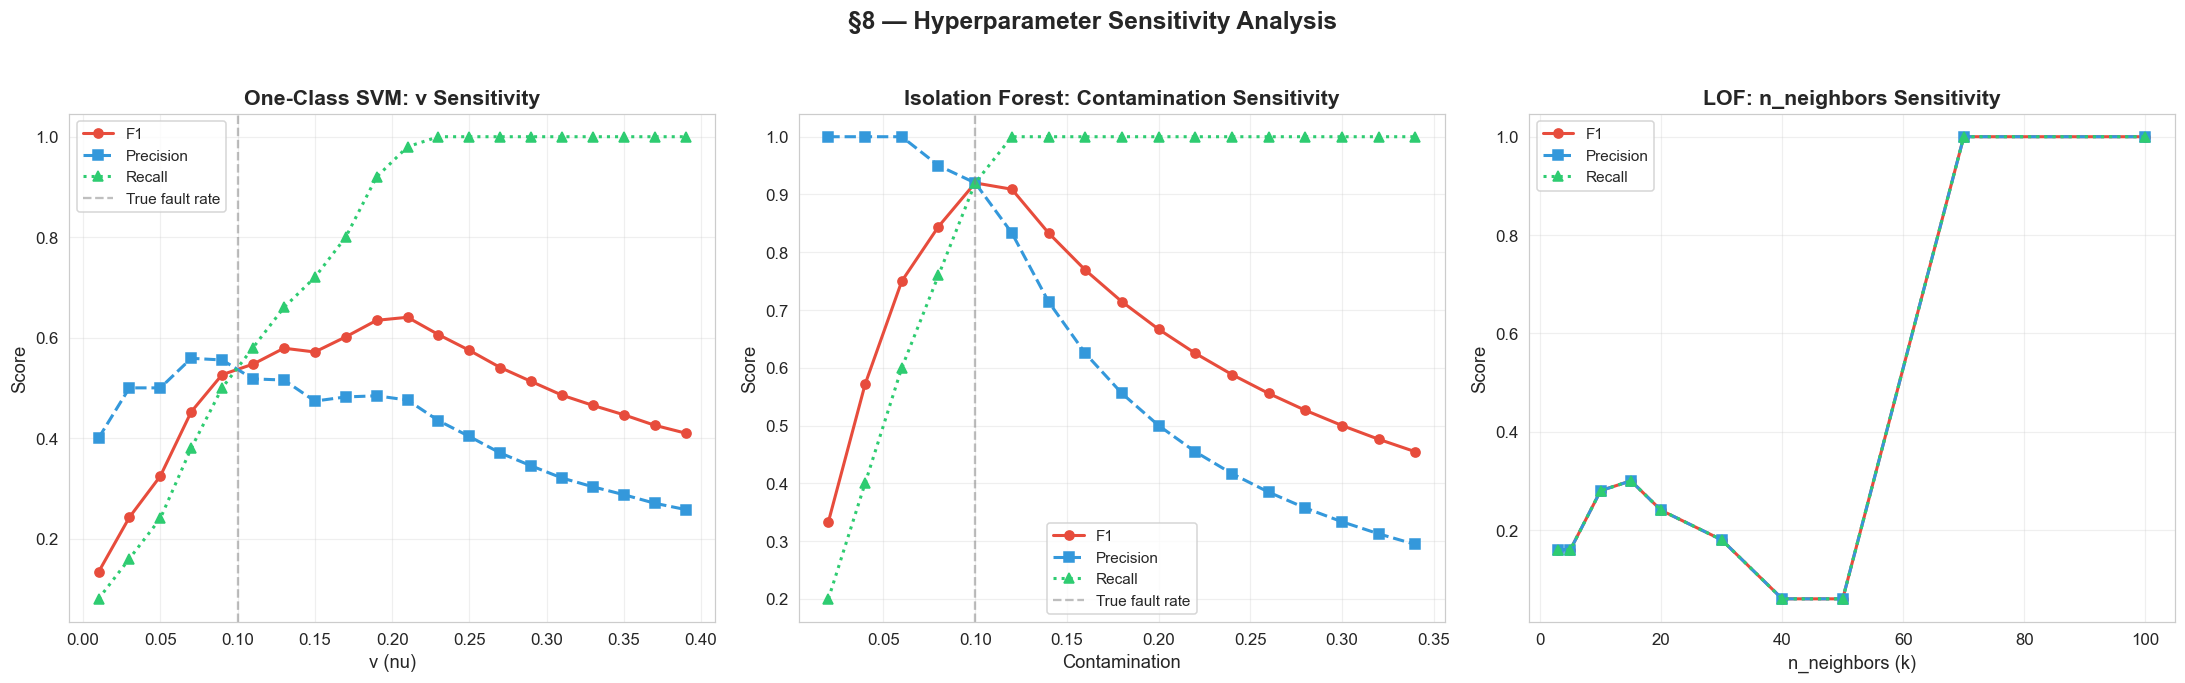

🔍 INSIGHTS:
   • SVM: Best F1 near ν ≈ true fault rate (0.10). Recall dominates at high ν.
   • IF:  Contamination directly controls precision-recall trade-off.
   • LOF: Fairly stable across k values; k=20 is a good default.


In [22]:
# ============================================================
# §8a — Hyperparameter Sweep: F1, Precision, Recall vs. Parameter
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# --- One-Class SVM: ν sweep ---
nu_values = np.arange(0.01, 0.40, 0.02)
ocsvm_metrics = {'nu': [], 'F1': [], 'Precision': [], 'Recall': []}
for nu in nu_values:
    model = OneClassSVM(kernel='rbf', gamma='scale', nu=nu)
    model.fit(X_scaled)
    y_p = (model.predict(X_scaled) == -1).astype(int)
    ocsvm_metrics['nu'].append(nu)
    ocsvm_metrics['F1'].append(f1_score(y_true, y_p, zero_division=0))
    ocsvm_metrics['Precision'].append(precision_score(y_true, y_p, zero_division=0))
    ocsvm_metrics['Recall'].append(recall_score(y_true, y_p, zero_division=0))

axes[0].plot(ocsvm_metrics['nu'], ocsvm_metrics['F1'], 'o-', color='#e74c3c', linewidth=2, label='F1')
axes[0].plot(ocsvm_metrics['nu'], ocsvm_metrics['Precision'], 's--', color='#3498db', linewidth=2, label='Precision')
axes[0].plot(ocsvm_metrics['nu'], ocsvm_metrics['Recall'], '^:', color='#2ecc71', linewidth=2, label='Recall')
axes[0].axvline(0.10, color='gray', linestyle='--', alpha=0.5, label='True fault rate')
axes[0].set_xlabel('ν (nu)')
axes[0].set_ylabel('Score')
axes[0].set_title('One-Class SVM: ν Sensitivity', fontweight='bold')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# --- Isolation Forest: contamination sweep ---
contam_values = np.arange(0.02, 0.35, 0.02)
if_metrics = {'contam': [], 'F1': [], 'Precision': [], 'Recall': []}
for c in contam_values:
    model = IsolationForest(n_estimators=200, contamination=c, random_state=SEED)
    model.fit(X_scaled)
    y_p = (model.predict(X_scaled) == -1).astype(int)
    if_metrics['contam'].append(c)
    if_metrics['F1'].append(f1_score(y_true, y_p, zero_division=0))
    if_metrics['Precision'].append(precision_score(y_true, y_p, zero_division=0))
    if_metrics['Recall'].append(recall_score(y_true, y_p, zero_division=0))

axes[1].plot(if_metrics['contam'], if_metrics['F1'], 'o-', color='#e74c3c', linewidth=2, label='F1')
axes[1].plot(if_metrics['contam'], if_metrics['Precision'], 's--', color='#3498db', linewidth=2, label='Precision')
axes[1].plot(if_metrics['contam'], if_metrics['Recall'], '^:', color='#2ecc71', linewidth=2, label='Recall')
axes[1].axvline(0.10, color='gray', linestyle='--', alpha=0.5, label='True fault rate')
axes[1].set_xlabel('Contamination')
axes[1].set_ylabel('Score')
axes[1].set_title('Isolation Forest: Contamination Sensitivity', fontweight='bold')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# --- LOF: n_neighbors sweep ---
k_values = [3, 5, 10, 15, 20, 30, 40, 50, 70, 100]
lof_metrics = {'k': [], 'F1': [], 'Precision': [], 'Recall': []}
for k in k_values:
    model = LocalOutlierFactor(n_neighbors=k, contamination=0.10)
    y_p = (model.fit_predict(X_scaled) == -1).astype(int)
    lof_metrics['k'].append(k)
    lof_metrics['F1'].append(f1_score(y_true, y_p, zero_division=0))
    lof_metrics['Precision'].append(precision_score(y_true, y_p, zero_division=0))
    lof_metrics['Recall'].append(recall_score(y_true, y_p, zero_division=0))

axes[2].plot(lof_metrics['k'], lof_metrics['F1'], 'o-', color='#e74c3c', linewidth=2, label='F1')
axes[2].plot(lof_metrics['k'], lof_metrics['Precision'], 's--', color='#3498db', linewidth=2, label='Precision')
axes[2].plot(lof_metrics['k'], lof_metrics['Recall'], '^:', color='#2ecc71', linewidth=2, label='Recall')
axes[2].set_xlabel('n_neighbors (k)')
axes[2].set_ylabel('Score')
axes[2].set_title('LOF: n_neighbors Sensitivity', fontweight='bold')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.suptitle('§8 — Hyperparameter Sensitivity Analysis', fontsize=16, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

print("🔍 INSIGHTS:")
print("   • SVM: Best F1 near ν ≈ true fault rate (0.10). Recall dominates at high ν.")
print("   • IF:  Contamination directly controls precision-recall trade-off.")
print("   • LOF: Fairly stable across k values; k=20 is a good default.")

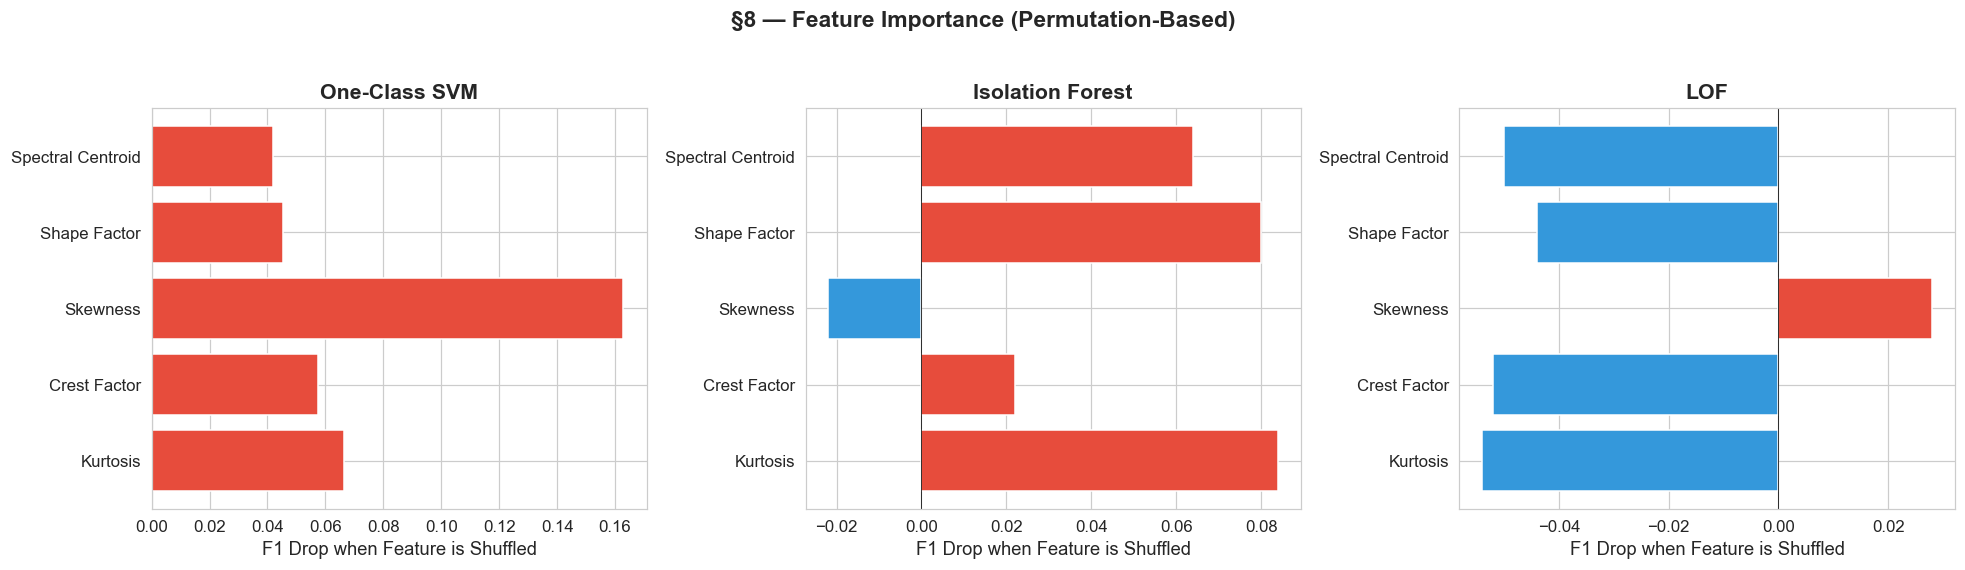

🔍 Red bars = important features (shuffling them hurts performance)
   Blue bars = less important (or even noisy) features
   Different models may rely on different features!


In [23]:
# ============================================================
# §8b — Feature Importance: Which features matter most?
# ============================================================

# Use permutation-style analysis: how much does F1 drop when we shuffle each feature?
from sklearn.base import clone

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
model_objs = {
    'One-Class SVM': OneClassSVM(kernel='rbf', gamma='scale', nu=0.10),
    'Isolation Forest': IsolationForest(n_estimators=200, contamination=0.10, random_state=SEED),
    'LOF': None  # Special handling
}

for ax_idx, (model_name, model_template) in enumerate(model_objs.items()):
    importances = []
    
    # Baseline F1
    if model_name == 'LOF':
        base_pred = (LocalOutlierFactor(n_neighbors=20, contamination=0.10).fit_predict(X_scaled) == -1).astype(int)
    else:
        model_template.fit(X_scaled)
        base_pred = (model_template.predict(X_scaled) == -1).astype(int)
    base_f1 = f1_score(y_true, base_pred, zero_division=0)
    
    for feat_idx in range(5):
        f1_drops = []
        for _ in range(10):  # 10 permutations
            X_perm = X_scaled.copy()
            np.random.shuffle(X_perm[:, feat_idx])
            
            if model_name == 'LOF':
                perm_pred = (LocalOutlierFactor(n_neighbors=20, contamination=0.10).fit_predict(X_perm) == -1).astype(int)
            else:
                m = clone(model_template)
                m.fit(X_perm)
                perm_pred = (m.predict(X_perm) == -1).astype(int)
            perm_f1 = f1_score(y_true, perm_pred, zero_division=0)
            f1_drops.append(base_f1 - perm_f1)
        importances.append(np.mean(f1_drops))
    
    # Plot
    colors_feat = ['#e74c3c' if imp > 0 else '#3498db' for imp in importances]
    bars = axes[ax_idx].barh(feature_names, importances, color=colors_feat, edgecolor='white')
    axes[ax_idx].set_xlabel('F1 Drop when Feature is Shuffled')
    axes[ax_idx].set_title(model_name, fontweight='bold')
    axes[ax_idx].axvline(0, color='black', linewidth=0.5)

plt.suptitle('§8 — Feature Importance (Permutation-Based)', fontsize=15, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

print("🔍 Red bars = important features (shuffling them hurts performance)")
print("   Blue bars = less important (or even noisy) features")
print("   Different models may rely on different features!")

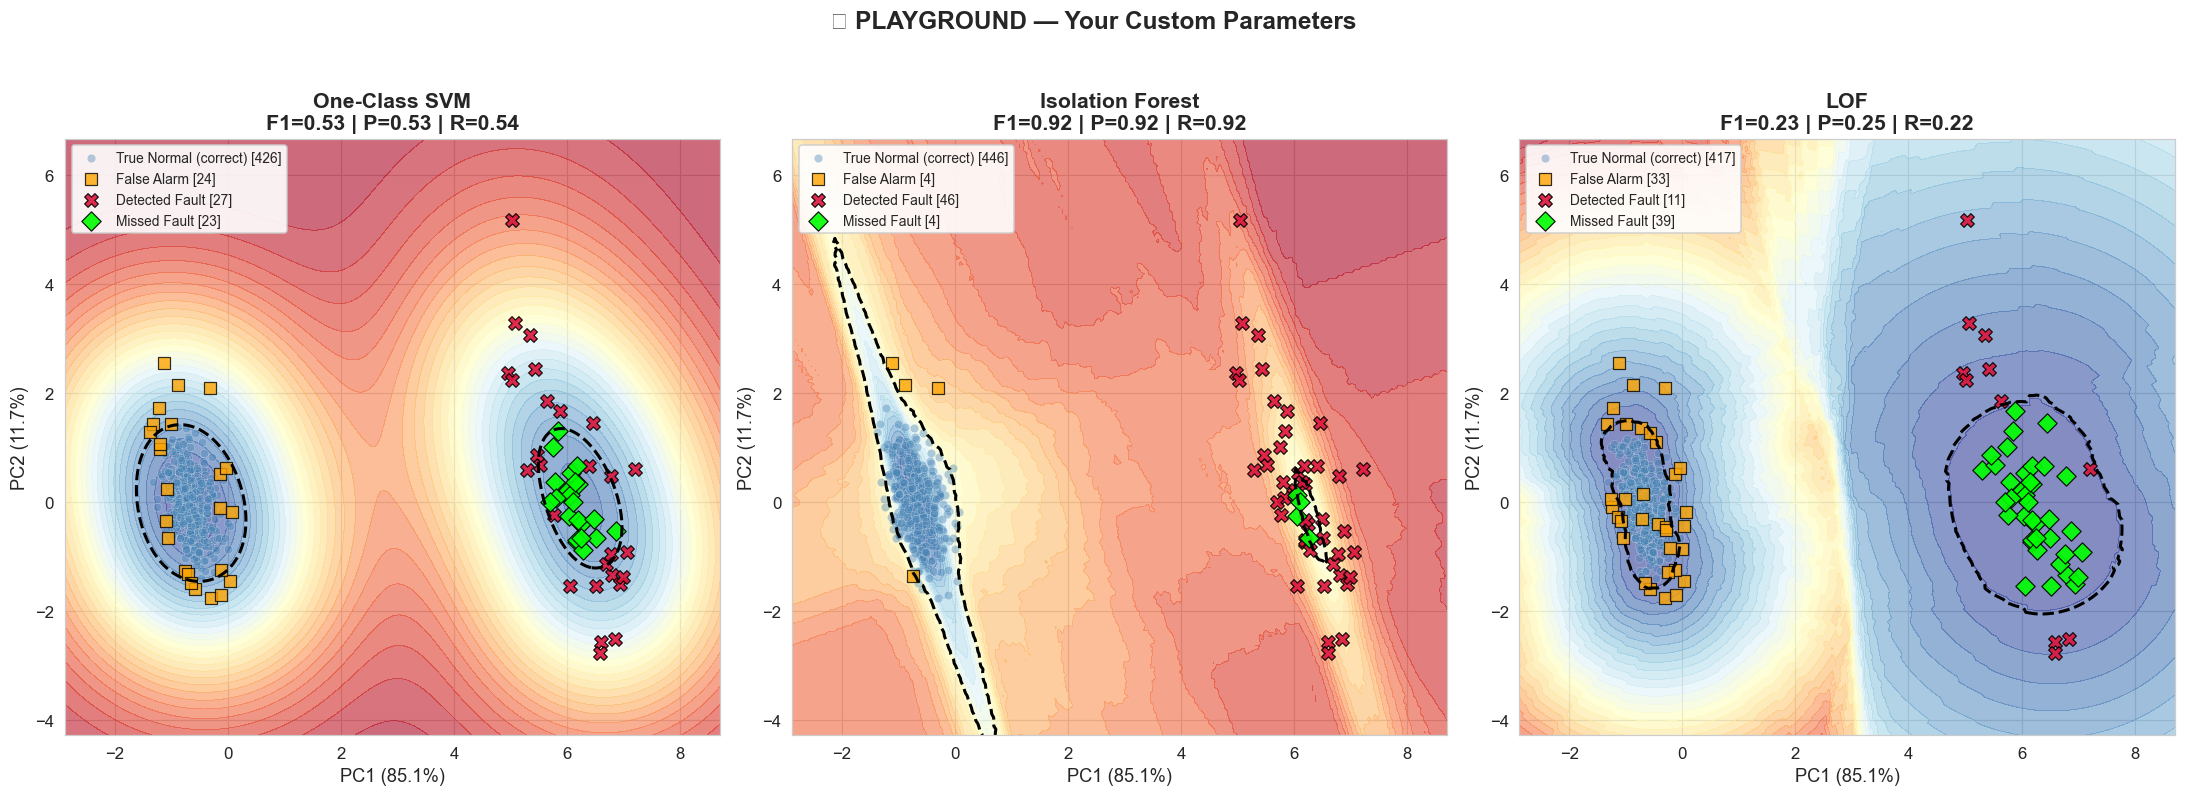


Model                         F1   Prec   Recall   Accuracy
One-Class SVM              0.535  0.529    0.540      0.906
Isolation Forest           0.920  0.920    0.920      0.984
LOF                        0.234  0.250    0.220      0.856


In [24]:
# ============================================================
# §8c — 🧪 PLAYGROUND: Change Parameters and Re-Run!
# ============================================================
# 
# ╔═══════════════════════════════════════════════════════════╗
# ║  🎮 MODIFY THESE VALUES AND RE-RUN THIS CELL!           ║
# ╚═══════════════════════════════════════════════════════════╝

# --- One-Class SVM ---
OCSVM_NU     = 0.10       # Try: 0.01, 0.05, 0.10, 0.20, 0.30
OCSVM_KERNEL = 'rbf'      # Try: 'rbf', 'sigmoid', 'poly'
OCSVM_GAMMA  = 'scale'    # Try: 'scale', 'auto', 0.01, 0.1, 1.0

# --- Isolation Forest ---
IF_N_ESTIMATORS   = 200   # Try: 10, 50, 100, 200, 500
IF_CONTAMINATION  = 0.10  # Try: 0.01, 0.05, 0.10, 0.20
IF_MAX_FEATURES   = 1.0   # Try: 0.5, 0.8, 1.0 (fraction of features per tree)

# --- Local Outlier Factor ---
LOF_N_NEIGHBORS   = 20    # Try: 3, 5, 10, 20, 50, 100
LOF_CONTAMINATION = 0.10  # Try: 0.01, 0.05, 0.10, 0.20
LOF_METRIC        = 'minkowski'  # Try: 'euclidean', 'manhattan', 'chebyshev'

# ======================== RUN ========================

svm_play = OneClassSVM(kernel=OCSVM_KERNEL, gamma=OCSVM_GAMMA, nu=OCSVM_NU)
svm_play.fit(X_scaled)
y_svm = (svm_play.predict(X_scaled) == -1).astype(int)

if_play = IsolationForest(n_estimators=IF_N_ESTIMATORS, contamination=IF_CONTAMINATION,
                          max_features=IF_MAX_FEATURES, random_state=SEED)
if_play.fit(X_scaled)
y_if = (if_play.predict(X_scaled) == -1).astype(int)

lof_play = LocalOutlierFactor(n_neighbors=LOF_N_NEIGHBORS, contamination=LOF_CONTAMINATION,
                               metric=LOF_METRIC, novelty=True)
lof_play.fit(X_scaled)
y_lof = (lof_play.predict(X_scaled) == -1).astype(int)

# --- Plot ---
fig, axes = plt.subplots(1, 3, figsize=(20, 7))

for ax, model, y_pred, name in zip(axes,
    [svm_play, if_play, lof_play],
    [y_svm, y_if, y_lof],
    ['One-Class SVM', 'Isolation Forest', 'LOF']):
    
    scores_play = model.decision_function(X_scaled)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    prec = precision_score(y_true, y_pred, zero_division=0)
    plot_decision_boundary_pca(model, X_pca, y_true, y_pred, scores_play,
                               f'{name}\nF1={f1:.2f} | P={prec:.2f} | R={rec:.2f}', ax)

plt.suptitle('🧪 PLAYGROUND — Your Custom Parameters', fontsize=16, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

# Summary table
print("\n" + "=" * 65)
print(f"{'Model':<25} {'F1':>6} {'Prec':>6} {'Recall':>8} {'Accuracy':>10}")
print("=" * 65)
for name, y_pred in [('One-Class SVM', y_svm), ('Isolation Forest', y_if), ('LOF', y_lof)]:
    print(f"{name:<25} {f1_score(y_true, y_pred, zero_division=0):>6.3f} "
          f"{precision_score(y_true, y_pred, zero_division=0):>6.3f} "
          f"{recall_score(y_true, y_pred, zero_division=0):>8.3f} "
          f"{accuracy_score(y_true, y_pred):>10.3f}")
print("=" * 65)

---
## §9 — Key Takeaways & Summary

### Algorithm Comparison

| Property | One-Class SVM | Isolation Forest | LOF |
|---|---|---|---|
| **Core idea** | Boundary around normal data in kernel space | Isolate anomalies via random partitioning | Compare local density to neighbors |
| **Time complexity** | $O(n^2)$ to $O(n^3)$ | $O(n \cdot T \cdot \log n)$ | $O(n^2)$ |
| **Key parameter** | ν (nu) | contamination / n_estimators | n_neighbors (k) |
| **Handles high-dim?** | With kernel trick | Yes (natively) | Degrades (curse of dimensionality) |
| **Needs clean training?** | Yes (novelty detection) | No | No (outlier detection) |
| **Boundary shape** | Smooth, kernel-dependent | Rectangular (axis-aligned) | Follows local density |
| **Best for** | Small data, complex boundaries | Large data, mixed features | Varying-density data |

### Practical Guidelines for Vibration Monitoring

1. **Start with Isolation Forest** — fast, robust, needs minimal tuning
2. **Use LOF** when you suspect density variations (e.g., different operating speeds)
3. **Use One-Class SVM** when you have clean baseline data and need a tight boundary
4. **Always check Recall** for safety-critical applications — missing a fault is worse than a false alarm
5. **Kurtosis and Crest Factor** are the most discriminative features for impulsive bearing faults
6. **Standardize features** before applying SVM or LOF (not strictly needed for IF, but good practice)

### 📚 Further Reading
- Schölkopf et al. (2001) — *Estimating the support of a high-dimensional distribution*
- Liu, Ting & Zhou (2008) — *Isolation Forest* (IEEE ICDM)
- Breunig et al. (2000) — *LOF: Identifying density-based local outliers* (ACM SIGMOD)
- Hariri et al. (2021) — *Extended Isolation Forest* (IEEE TKDE)
- Randall & Antoni (2011) — *Rolling element bearing diagnostics—A tutorial* (Mechanical Systems and Signal Processing)